# Bayesian neural networks: predictions, uncertainty, and active learning — solutions

Skoltech · Bayesian machine learning

The Laplace seminar averaged predictions over a Gaussian approximation to a
parameter posterior. A Bayesian neural network asks the same question with
neural-network weights: how should predictions change when more than one
plausible function remains after observing data?

We reuse the first example from `spring_2025/seminar_ue_en.ipynb`: a binary
classifier on four one-dimensional intervals. The geometry makes individual
dropout functions and their disagreement visible. Three tasks implement
Monte Carlo prediction, an uncertainty decomposition, and label acquisition.
Task 4 extends the comparison to MNIST with a dropout CNN on a GPU.

Tasks 1–3 form a 90-minute core. Task 4 is a separate practical, and the two
appendices explore data geometry, Monte Carlo budget, and batch redundancy.
Prerequisites are Bayes' rule, categorical probabilities, expectation,
entropy, and basic PyTorch. No previous active-learning code is required.


## Setup

Use Python 3.9+ with NumPy, Matplotlib, PyTorch, IPython, and a notebook
interface. Task 4 also needs a matching torchvision installation and a CUDA
GPU; it downloads public MNIST once and then reuses a local data cache.
Install `requirements.txt` in your chosen environment. Run cells in order.

Unfinished tasks raise `NotImplementedError` and their dependent experiments
are skipped. Incorrect completed implementations fail their checks visibly.
`RUN_MNIST` enables the GPU practical; without CUDA its training is explicitly
skipped. `RUN_APPENDICES` enables additional controlled experiments.

All small examples run on a CPU. Fixed seeds make comparisons repeatable on
a given software stack; last digits can differ between versions or devices.
`SAVE_FIGURES` exports the solution plots for the printable teacher's guide.


In [1]:
from contextlib import contextmanager
from pathlib import Path
import copy
import math
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display, Markdown

RUN_MNIST = True
RUN_APPENDICES = True
SAVE_FIGURES = True
TOY_TRAIN_STEPS = 4000
TOY_AL_STEPS = 1000
MC_DRAWS = 200
DEVICE = torch.device("cpu")
torch.set_num_threads(1)
torch.manual_seed(2026)
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update(
    {
        "font.size": 11,
        "axes.grid": True,
        "grid.alpha": 0.18,
        "axes.titleweight": "normal",
        "figure.figsize": (9, 3.5),
    }
)
completed = set()
BLUE, ORANGE, GREEN = "#2369a1", "#c77516", "#2b8868"


def table(headers, rows):
    def fmt(value):
        return f"{value:.5g}" if isinstance(value, (float, np.floating)) else str(value)

    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
    ]
    lines += ["| " + " | ".join(map(fmt, row)) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def check_task(label, test):
    completed.discard(label)
    try:
        test()
    except NotImplementedError:
        print(f"Task {label}: unfinished; dependent experiments will be skipped.")
        return False
    completed.add(label)
    print(f"Task {label}: checks passed.")
    return True


def ready(*labels):
    missing = [str(label) for label in labels if label not in completed]
    if missing:
        print("Complete Task " + ", ".join(missing) + " to run this experiment.")
    return not missing


def assert_close(actual, expected, atol=1e-8, rtol=1e-8):
    torch.testing.assert_close(actual, expected, atol=atol, rtol=rtol)


def show_figure(fig, name):
    if SAVE_FIGURES:
        assets = Path("assets")
        assets.mkdir(exist_ok=True)
        fig.savefig(assets / f"{name}.pdf", bbox_inches="tight")
        fig.savefig(assets / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


print(
    f"PyTorch {torch.__version__}; small examples on {DEVICE}; CUDA available: {torch.cuda.is_available()}"
)


PyTorch 2.4.1+cu121; small examples on cpu; CUDA available: True


## 1. From uncertain weights to uncertain predictions

For inputs $x$ and class $y\in\{0,\ldots,C-1\}$, a neural network with weights
$w$ defines logits $a_w(x)$ and categorical probabilities
$$p(y=c\mid x,w)=\operatorname{softmax}(a_w(x))_c.$$
Conditioning on the observed inputs requires no assumption that their
distribution is uniform. Given labelled observations $\mathcal D$, a weight
prior and likelihood define
$$p(w\mid\mathcal D)\propto p(w)\prod_{i=1}^N p(y_i\mid x_i,w).$$
Prediction integrates weights rather than inserting just one fitted vector:
$$p(y=c\mid x,\mathcal D)=\mathbb E_{p(w\mid\mathcal D)}p(y=c\mid x,w).$$
A nonlinear network usually makes this posterior intractable. If an
approximation $q(w)$ is available, independent draws give
$$\bar p_c(x)=\frac1T\sum_{t=1}^T p(y=c\mid x,w_t),\qquad w_t\sim q.$$
Average the probabilities, not the logits. In general
$\operatorname{softmax}(\mathbb E a_w)\ne\mathbb E\operatorname{softmax}(a_w)$.
The predicted class is $\arg\max_c\bar p_c$; it is not the MAP estimate of
the weights. More draws reduce numerical integration error under $q$ but
do not make $q$ equal to the desired posterior.

### Monte Carlo dropout

Dropout multiplies hidden features by random Bernoulli masks. During training
this regularizes the network. Retaining dropout during prediction defines a
distribution over stochastic networks. Under particular modelling and
regularization assumptions this has a variational interpretation [1].
For a general prior, variational inference would maximize
$$\mathcal L(q)=\mathbb E_q\left[\sum_i\log p(y_i\mid x_i,w)\right]
                  -D_{\rm KL}(q\Vert p(w)).$$
Our practical uses dropout and L2 regularization as an approximate method;
its masks are not exact posterior weight samples, and changing an arbitrary
dropout rate or weight decay does not establish posterior calibration.


## 2. Reuse the one-dimensional example

Keep the original interval dictionary and 30 equally spaced observations
per interval:
$$\begin{aligned}
y=0:&\quad [-5,-3]\ \text{and}\ [1,2.5],\\
y=1:&\quad [-3,-2]\ \text{and}\ [2.5,5].
\end{aligned}$$
There are 120 observations. `linspace` includes both ends, so the shared
points $-3$ and $2.5$ each appear with opposing labels. The central gap
$(-2,1)$ contains no observations. We preserve these details rather than
silently changing the motivating example. The training grid is deterministic;
it is not a claim that these 120 inputs were iid uniform draws.

The network follows the same architecture:
`1 → 10 → 50 → 20 → 1`, with sigmoid hidden activations and dropout probability
0.2 before the second hidden sigmoid. The input scaling is the original
$u=(x+5)/10$. For numerical stability, the network returns two centred logits
$(-a/2,a/2)$ instead of applying a final sigmoid; class-1 probability is still
$\operatorname{sigmoid}(a)$. Cross entropy is the corresponding binary log loss.


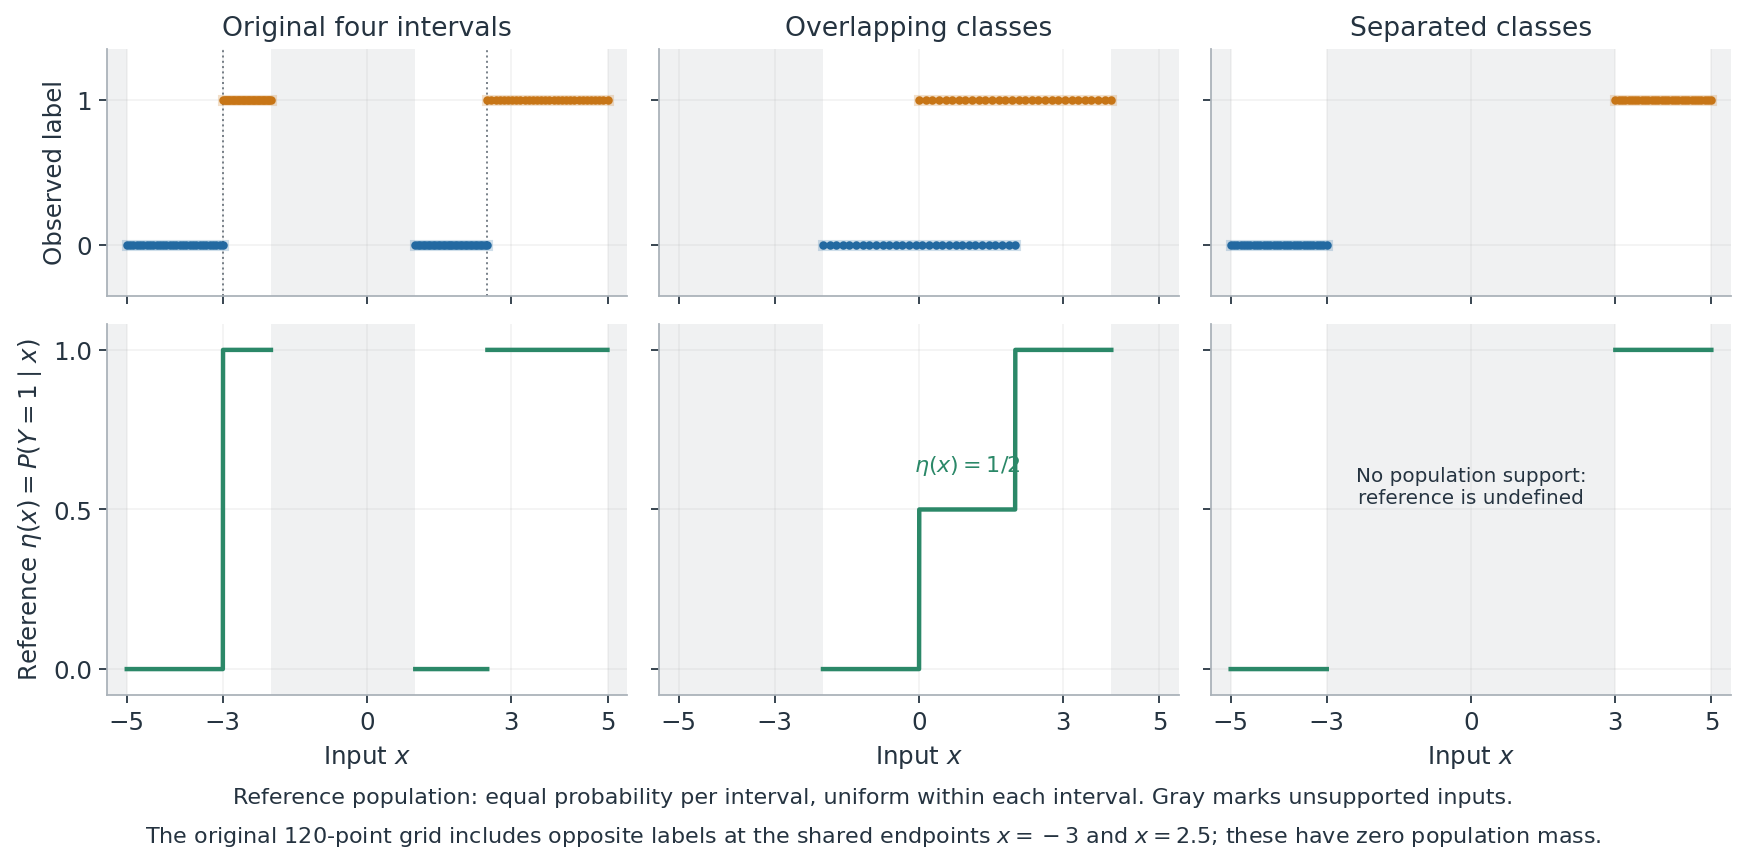

The original observation geometry has a central gap and two shared endpoints. The reference distributions for overlap/gap experiments are defined separately; a conditional label probability is undefined where the input has zero density.


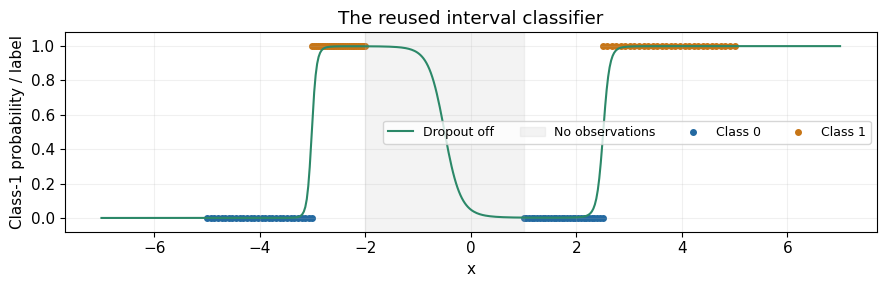

In [2]:
END_POINTS = {0: [[-5, -3], [1, 2.5]], 1: [[-3, -2], [2.5, 5]]}


def interval_data(end_points=END_POINTS, points_per_interval=30):
    x, y = [], []
    for label, intervals in end_points.items():
        for left, right in intervals:
            x.append(torch.linspace(left, right, points_per_interval))
            y.append(torch.full((points_per_interval,), label, dtype=torch.long))
    return torch.cat(x)[:, None], torch.cat(y)


class SharedMaskDropout(nn.Module):
    """Ordinary training dropout; one feature mask per MC function draw."""

    def __init__(self, p=0.2):
        super().__init__()
        self.p = p
        self.mc_active = False
        self.mc_mask = None

    def forward(self, x):
        if self.mc_active:
            if self.mc_mask is None:
                self.mc_mask = torch.empty_like(x[:1]).bernoulli_(1 - self.p) / (1 - self.p)
            return x * self.mc_mask
        return torch.nn.functional.dropout(x, p=self.p, training=self.training)


@contextmanager
def sampled_model(model):
    """One stochastic function; freeze normalization, then restore every mode."""
    modes = [(module, module.training) for module in model.modules()]
    shared = [
        (module, module.mc_active, module.mc_mask)
        for module in model.modules()
        if isinstance(module, SharedMaskDropout)
    ]
    try:
        model.eval()
        for module in model.modules():
            if isinstance(module, SharedMaskDropout):
                module.mc_active, module.mc_mask = True, None
            elif isinstance(module, (nn.Dropout, nn.Dropout1d, nn.Dropout2d, nn.Dropout3d)):
                module.train()
        with torch.no_grad():
            yield
    finally:
        for module, active, mask in shared:
            module.mc_active, module.mc_mask = active, mask
        for module, training in modes:
            module.training = training


class ToyDropoutNet(nn.Module):
    def __init__(self, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 10),
            nn.Sigmoid(),
            nn.Linear(10, 50),
            SharedMaskDropout(dropout),
            nn.Sigmoid(),
            nn.Linear(50, 20),
            nn.Sigmoid(),
            nn.Linear(20, 1),
        )

    def forward(self, x):
        a = self.net((x + 5) / 10)
        return torch.cat([-0.5 * a, 0.5 * a], dim=-1)


class ActiveToyNet(nn.Module):
    """Smaller network for fitting repeatedly to very small labelled subsets."""

    def __init__(self, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 32),
            nn.Tanh(),
            SharedMaskDropout(dropout),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 2),
        )

    def forward(self, x):
        return self.net(x / 5)


def fit_toy(x, y, seed, steps=TOY_TRAIN_STEPS, dropout=0.2, active=False):
    torch.manual_seed(seed)
    model = ActiveToyNet(dropout) if active else ToyDropoutNet(dropout)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-2, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=0.03 if active else 0.1,
        total_steps=steps,
        div_factor=10,
        final_div_factor=100,
    )
    history = []
    model.train()
    for step in range(steps):
        loss = torch.nn.functional.cross_entropy(model(x), y)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        scheduler.step()
        if step % 400 == 0 or step == steps - 1:
            history.append((step, loss.item()))
    model.eval()
    return model, np.array(history)


x_train, y_train = interval_data()
assert x_train.shape == (120, 1)
assert torch.bincount(y_train).tolist() == [60, 60]
toy_model, toy_history = fit_toy(x_train, y_train, seed=11)
x_grid = torch.linspace(-7, 7, 501)[:, None]
with torch.no_grad():
    deterministic_probability = toy_model(x_grid).softmax(-1)[:, 1]
fig, ax = plt.subplots(figsize=(9, 3))
for c, color in [(0, BLUE), (1, ORANGE)]:
    ax.scatter(
        x_train[y_train == c, 0], y_train[y_train == c], color=color, s=16, label=f"Class {c}"
    )
ax.plot(x_grid[:, 0], deterministic_probability, color=GREEN, label="Dropout off")
ax.axvspan(-2, 1, color="0.7", alpha=0.15, label="No observations")
ax.set(
    xlabel="x",
    ylabel="Class-1 probability / label",
    ylim=(-0.08, 1.08),
    title="The reused interval classifier",
)
ax.legend(ncol=4, fontsize=9)
plt.tight_layout()
show_figure(fig, "toy_observations")


## Task 1 — Average stochastic predictions

Complete `mc_probabilities(model, inputs, n_draws=200)` and return `(T,N,C)`.
The model returns raw class logits. The supplied `sampled_model` context
activates dropout, freezes normalization layers, disables gradients, and
restores previous modes even after an exception. Each context represents
one new draw; put it inside the loop and apply softmax over classes.

For the toy network, the supplied shared mask is held fixed for every input
in a draw. Connecting those predictions across the grid therefore draws one
coherent function. Ordinary PyTorch dropout uses independent masks for rows
in a batch: it estimates pointwise marginals but does not produce coherent
function curves. Task 4 will explicitly use that pointwise interpretation.

Explain why the deterministic evaluation curve need not equal the MC mean,
and why averaging logits would compute a different quantity.


In [3]:
def mc_probabilities(model, inputs, n_draws=200):
    """Raw inputs (N,d) -> probability draws (T,N,C), with no gradient history."""
    if n_draws < 1 or len(inputs) == 0:
        raise ValueError("Need at least one draw and one input")
    draws = []
    for _ in range(n_draws):
        with sampled_model(model):
            draws.append(model(inputs).softmax(dim=-1))
    return torch.stack(draws, dim=0)


In [4]:
def test_mc_probabilities():
    class Constant(nn.Module):
        def __init__(self):
            super().__init__()
            self.value = nn.Parameter(torch.tensor([-2.0, 1.0], dtype=torch.float64))
            self.calls = 0

        def forward(self, x):
            self.calls += 1
            return self.value.expand(len(x), -1)

    model = Constant()
    p = mc_probabilities(model, torch.zeros(4, 1, dtype=torch.float64), 5)
    assert p.shape == (5, 4, 2) and p.dtype == torch.float64 and not p.requires_grad
    assert model.calls == 5
    assert_close(p, model.value.softmax(-1).expand(5, 4, 2))
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(12)
        net = ToyDropoutNet().double()
        net.train()
        net.net[0].eval()  # Deliberately mixed modes.
        before = [m.training for m in net.modules()]
        shared = next(m for m in net.modules() if isinstance(m, SharedMaskDropout))
        p = mc_probabilities(net, torch.ones(4, 1, dtype=torch.float64), 64)
        assert [m.training for m in net.modules()] == before
        assert not shared.mc_active and shared.mc_mask is None
        assert_close(p, p[:, :1].expand_as(p))  # Same function at repeated x.
        assert p[:, 0, 1].std() > 1e-6
        assert_close(p.sum(-1), torch.ones(64, 4, dtype=torch.float64))
        bn_model = nn.Sequential(nn.BatchNorm1d(1), nn.Linear(1, 2)).double()
        bn_model.train()
        before_mean = bn_model[0].running_mean.clone()
        mc_probabilities(bn_model, torch.ones(4, 1, dtype=torch.float64), 3)
        assert bn_model.training and bn_model[0].training
        assert_close(bn_model[0].running_mean, before_mean)
        try:
            with sampled_model(net):
                raise RuntimeError("Restoration check")
        except RuntimeError:
            pass
        assert [m.training for m in net.modules()] == before
        assert not shared.mc_active and shared.mc_mask is None


check_task(1, test_mc_probabilities)


Task 1: checks passed.


True

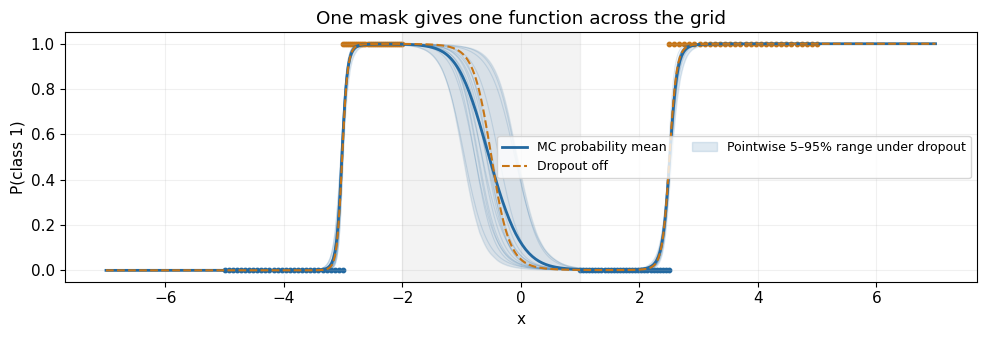

| x | MC mean | Component-probability SD | MC SE of mean |
| --- | --- | --- | --- |
| -4.004 | 0.00014874 | 7.6014e-05 | 5.375e-06 |
| -1.008 | 0.86839 | 0.15161 | 0.010721 |
| 1.708 | 0.0023211 | 0.00089399 | 6.3215e-05 |
| 5.992 | 0.99975 | 4.1675e-05 | 2.9468e-06 |

In [5]:
if ready(1):
    torch.manual_seed(13)
    toy_draws = mc_probabilities(toy_model, x_grid, MC_DRAWS)
    positive = toy_draws[:, :, 1]
    mean_probability = positive.mean(0)
    low, high = torch.quantile(positive, positive.new_tensor([0.05, 0.95]), dim=0)
    mean_se = positive.std(0) / math.sqrt(MC_DRAWS)
    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.axvspan(-2, 1, color="0.7", alpha=0.15)
    for draw in positive[:15]:
        ax.plot(x_grid[:, 0], draw, color=BLUE, alpha=0.16, lw=0.8)
    ax.fill_between(
        x_grid[:, 0],
        low,
        high,
        color=BLUE,
        alpha=0.14,
        label="Pointwise 5–95% range under dropout",
    )
    ax.plot(x_grid[:, 0], mean_probability, color=BLUE, lw=2, label="MC probability mean")
    ax.plot(
        x_grid[:, 0], deterministic_probability, color=ORANGE, ls="--", label="Dropout off"
    )
    for label, color in [(0, BLUE), (1, ORANGE)]:
        ax.scatter(x_train[y_train == label, 0], y_train[y_train == label], color=color, s=10)
    ax.set(
        xlabel="x",
        ylabel="P(class 1)",
        ylim=(-0.05, 1.05),
        title="One mask gives one function across the grid",
    )
    ax.legend(ncol=2, fontsize=9)
    plt.tight_layout()
    show_figure(fig, "toy_mc_predictions")
    selected = [
        int(torch.argmin((x_grid[:, 0] - value).abs())) for value in [-4.0, -1.0, 1.7, 6.0]
    ]
    table(
        ["x", "MC mean", "Component-probability SD", "MC SE of mean"],
        [
            [
                x_grid[i, 0].item(),
                mean_probability[i].item(),
                positive[:, i].std().item(),
                mean_se[i].item(),
            ]
            for i in selected
        ],
    )


Interpretation. The MC mean averages probabilities under the dropout distribution. Turning
dropout off uses a deterministic network, and nonlinear activations prevent
the two operations from commuting. The shaded component-probability range
describes variation under the approximation; it is not an MC confidence
interval for its mean and is not an exact posterior credible band. The MC SE
describes numerical integration error at one fixed input. More draws reduce
that error while leaving the fitted dropout distribution unchanged.


## 3. Two routes to the same uncertain prediction

For one input, write $p_t\in[0,1]^C$ for the class probability vector of draw
$t$, and $\bar p=T^{-1}\sum_t p_t$. Categorical entropy is
$$H(p)=-\sum_{c=1}^C p_c\log p_c,\qquad 0\log0=0.$$
Use natural logs, so binary entropy is at most $\log2$ nats. Under a chosen
weight distribution $q$, the predictive entropy decomposes as
$$\underbrace{H(\mathbb E_q p_w)}_{\text{predictive entropy}}
=\underbrace{\mathbb E_q H(p_w)}_{\text{expected conditional entropy}}
 +\underbrace{I_q(Y;W\mid x,\mathcal D)}_{\text{mutual information}}.$$
Equivalently,
$$I_q=\mathbb E_q\,D_{\rm KL}\big(p(y\mid x,W)\Vert\mathbb E_q p(y\mid x,W)\big).$$
The first term is large when individual models each predict ambiguously.
The MI term is large when their class probabilities disagree. These are
often called aleatoric and epistemic components, respectively. The labels
are relative to the model and $q$: the first is not automatically the true
irreducible data uncertainty, and a small MI need not show that a region is
well understood.

Replace expectations with averages over draws:
$$\widehat I=H(\bar p)-\frac1T\sum_tH(p_t).$$
For the empirical mixture this is nonnegative up to roundoff. With iid draws,
the average conditional entropy is unbiased for its $q$ expectation, whereas
$H(\bar p)$ and consequently $\widehat I$ are generally downward biased by
concavity. At $T=1$, $\widehat I=0$ for every input.


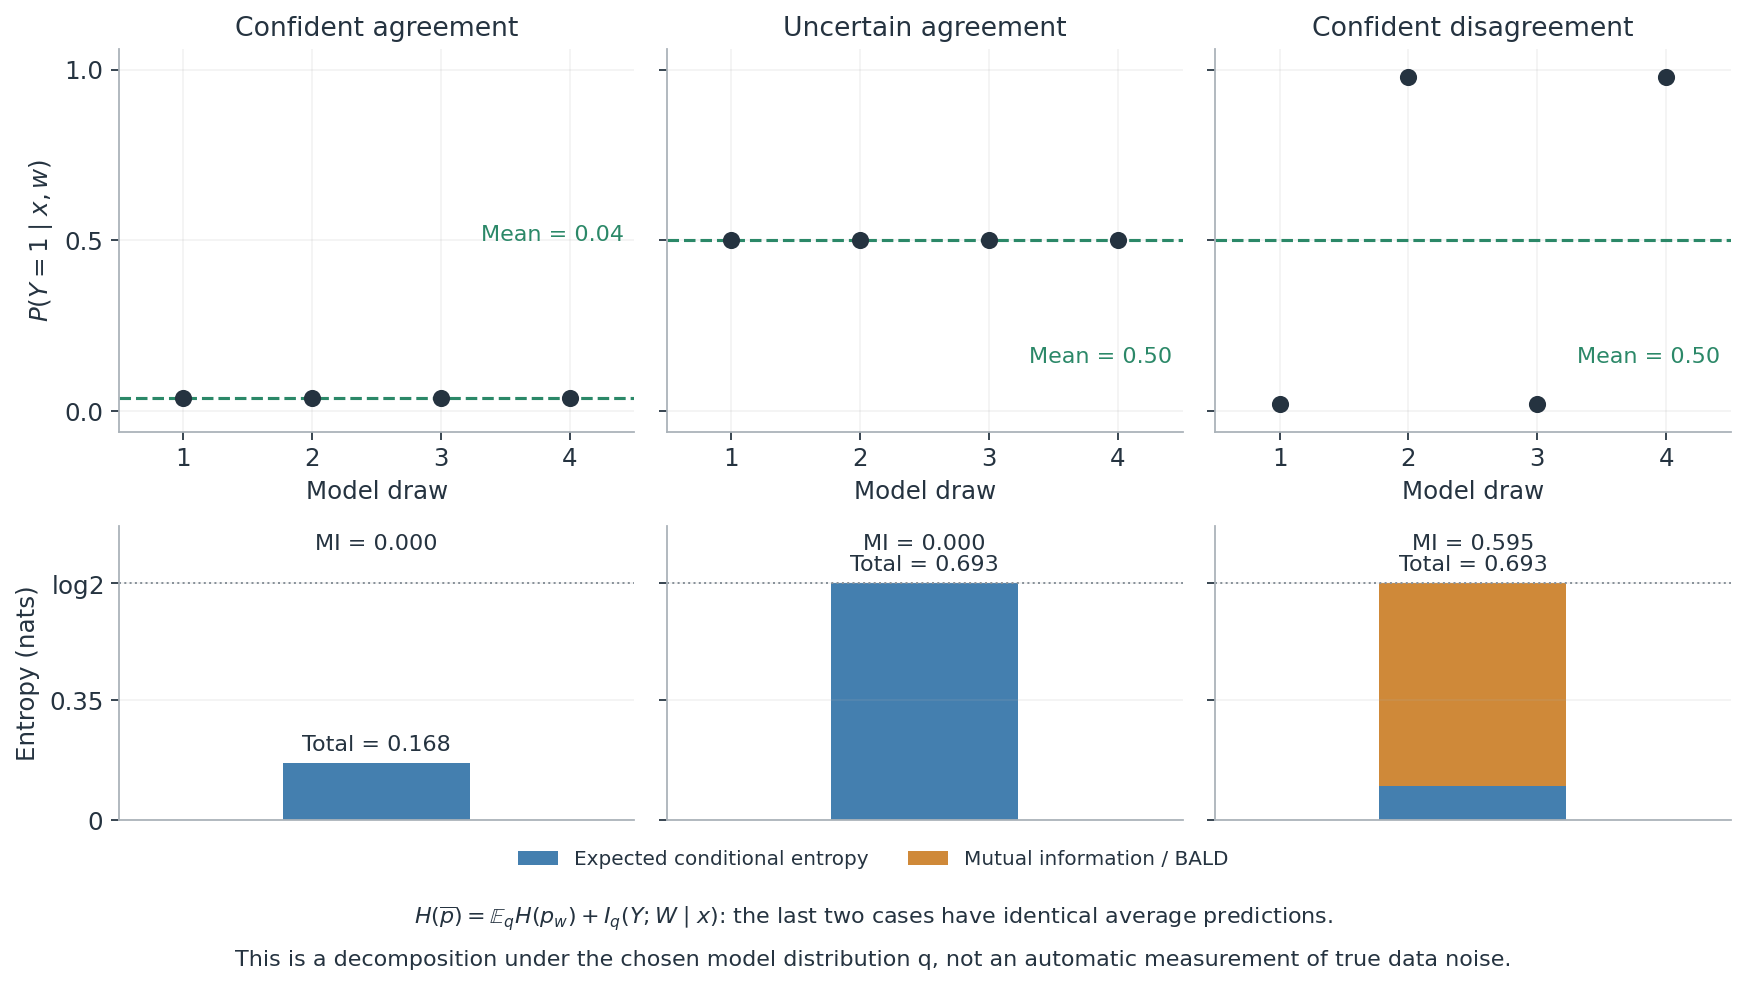

Ambiguous agreement and confident disagreement can have the same predictive mean and entropy. Expected conditional entropy and mutual information distinguish them under the chosen distribution of models.


## Task 2 — Compute entropy and disagreement

1. Implement `categorical_entropy(probabilities)` with a sum over the last
   axis. Handle zero probabilities without `NaN` values.
2. Implement `uncertainty_terms(draws)` for `(T,N,C)` with `T >= 2`. Return
   the mean probability, predictive entropy, expected conditional entropy,
   mutual information, and pointwise MC SE of the mean probabilities.
3. Compare an ensemble where every model predicts `(0.5,0.5)` with an
   ensemble split equally between `(1,0)` and `(0,1)`.

Use `std(..., unbiased=True)/sqrt(T)` for the probability MC SE. Only numerical
roundoff should require clamping a tiny negative MI; do not replace MI by
entropy or predictive variance.


In [6]:
def validate_probabilities(probabilities):
    if (
        not probabilities.is_floating_point()
        or probabilities.ndim < 1
        or probabilities.shape[-1] < 2
    ):
        raise ValueError("Expected floating class probabilities with at least two classes")
    if (
        not torch.isfinite(probabilities).all()
        or (probabilities < 0).any()
        or (probabilities > 1).any()
    ):
        raise ValueError("Probabilities must be finite and in [0,1]")
    if not torch.allclose(
        probabilities.sum(-1), torch.ones_like(probabilities[..., 0]), atol=1e-5, rtol=1e-5
    ):
        raise ValueError("Class probabilities must sum to one")


In [7]:
def categorical_entropy(probabilities):
    """(...,C) -> entropy (...), in nats, with 0 log 0 = 0."""
    validate_probabilities(probabilities)
    safe = probabilities.clamp_min(torch.finfo(probabilities.dtype).tiny)
    return -(probabilities * safe.log()).sum(dim=-1)


def uncertainty_terms(draws):
    """(T,N,C), T>=2 -> dictionary of predictive and MC-integration summaries."""
    if draws.ndim != 3 or draws.shape[0] < 2:
        raise ValueError("Expected (T,N,C) with at least two draws")
    validate_probabilities(draws)
    mean = draws.mean(dim=0)
    predictive = categorical_entropy(mean)
    expected = categorical_entropy(draws).mean(dim=0)
    return {
        "mean_probability": mean,
        "predictive_entropy": predictive,
        "expected_entropy": expected,
        "mutual_information": (predictive - expected).clamp_min(0),
        "probability_mc_se": draws.std(dim=0, unbiased=True) / math.sqrt(draws.shape[0]),
    }


In [8]:
def test_uncertainty():
    point_mass = torch.tensor([[1.0, 0.0], [0.0, 1.0]], dtype=torch.float64)
    assert_close(categorical_entropy(point_mass), torch.zeros(2, dtype=torch.float64))
    uncertain = torch.full((4, 1, 2), 0.5, dtype=torch.float64)
    disagreement = point_mass.repeat(2, 1)[:, None]
    a, b = uncertainty_terms(uncertain), uncertainty_terms(disagreement)
    log2 = uncertain.new_tensor(math.log(2))
    assert_close(a["mean_probability"], b["mean_probability"])
    assert_close(a["predictive_entropy"][0], log2)
    assert_close(a["expected_entropy"][0], log2)
    assert_close(a["mutual_information"], torch.zeros(1, dtype=torch.float64))
    assert_close(b["expected_entropy"], torch.zeros(1, dtype=torch.float64))
    assert_close(b["mutual_information"][0], log2)
    assert_close(
        b["probability_mc_se"], torch.full((1, 2), 1 / math.sqrt(12), dtype=torch.float64)
    )
    draws = torch.tensor(
        [
            [[0.8, 0.1, 0.1], [0.2, 0.3, 0.5]],
            [[0.1, 0.2, 0.7], [0.5, 0.4, 0.1]],
            [[0.4, 0.4, 0.2], [0.3, 0.3, 0.4]],
        ],
        dtype=torch.float64,
    )
    terms = uncertainty_terms(draws)
    mean = draws.mean(0)
    # Independent KL identity checks both axes and the entropy difference.
    kl = (draws * (draws / mean).log()).sum(-1).mean(0)
    assert_close(terms["mutual_information"], kl)
    assert terms["mean_probability"].shape == terms["probability_mc_se"].shape == (2, 3)
    assert terms["predictive_entropy"].shape == terms["expected_entropy"].shape == (2,)
    try:
        uncertainty_terms(draws[:1])
    except ValueError:
        pass
    else:
        raise AssertionError("One draw has no sample-variance MC SE")


check_task(2, test_uncertainty)


Task 2: checks passed.


True

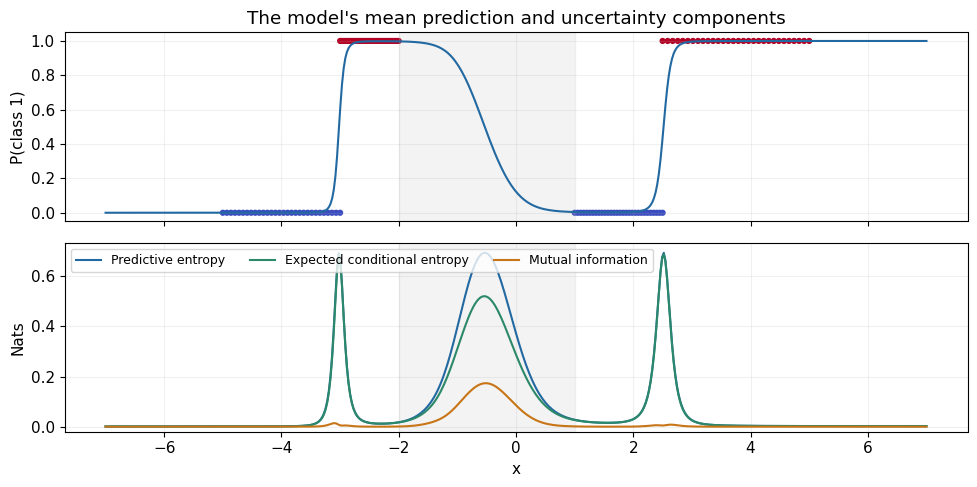

| x | Predictive entropy | Conditional entropy | MI |
| --- | --- | --- | --- |
| -4.004 | 0.0014597 | 0.0014448 | 1.4895e-05 |
| -1.008 | 0.38944 | 0.30524 | 0.084202 |
| 1.708 | 0.016397 | 0.016254 | 0.00014344 |
| 5.992 | 0.0023182 | 0.0023151 | 3.1544e-06 |

In [9]:
if ready(1, 2):
    toy_uncertainty = uncertainty_terms(toy_draws)
    fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
    axes[0].plot(x_grid[:, 0], toy_uncertainty["mean_probability"][:, 1], color=BLUE)
    axes[0].scatter(x_train[:, 0], y_train, c=y_train, cmap="coolwarm", s=12)
    axes[0].set(
        ylabel="P(class 1)", title="The model's mean prediction and uncertainty components"
    )
    for key, label, color in [
        ("predictive_entropy", "Predictive entropy", BLUE),
        ("expected_entropy", "Expected conditional entropy", GREEN),
        ("mutual_information", "Mutual information", ORANGE),
    ]:
        axes[1].plot(x_grid[:, 0], toy_uncertainty[key], color=color, label=label)
    for ax in axes:
        ax.axvspan(-2, 1, color="0.7", alpha=0.15)
    axes[1].set(xlabel="x", ylabel="Nats", ylim=(-0.02, math.log(2) + 0.04))
    axes[1].legend(fontsize=9, ncol=3)
    plt.tight_layout()
    show_figure(fig, "toy_uncertainty")
    table(
        ["x", "Predictive entropy", "Conditional entropy", "MI"],
        [
            [
                x_grid[i, 0].item(),
                toy_uncertainty["predictive_entropy"][i].item(),
                toy_uncertainty["expected_entropy"][i].item(),
                toy_uncertainty["mutual_information"][i].item(),
            ]
            for i in selected
        ],
    )


Interpretation questions. Where does this fitted dropout model disagree?
Does the gap always have larger MI than observed regions? Can two inputs
with the same predictive entropy suggest different reasons for uncertainty?
How does increasing the number of MC draws differ from collecting labels?


Interpretation. Inspect all three curves together. High expected conditional entropy means
that individual stochastic models tend to be ambiguous; high MI means their
probability vectors differ. The decomposition holds under this fitted
approximation, so it does not prove what the true noise level is. Missing
data do not force this architecture to disagree, and extrapolation can remain
confident. More draws improve integration under the same approximation;
additional informative labels can change the fitted model itself.


## 4. When should we ask for another label?

In pool-based active learning the inputs of an unlabelled pool are available,
but their labels can be requested only through an oracle. A labelling budget
counts the initial labelled examples and every newly queried example.
Acquisition receives pool inputs and model predictions, never hidden labels.

Predictive-entropy acquisition selects large $H(\bar p(x))$. BALD instead
selects large disagreement [2,3]:
$$a_{\rm BALD}(x)=I_q(Y;W\mid x,\mathcal D).$$
For a Bayesian posterior, this is the expected information gained about
weights by observing the label. Under an approximate $q$, define
$$q_y(w\mid x)\propto q(w)p(y\mid x,w).$$
Then $I_q=\mathbb E_{y\sim\bar p}\,D_{\rm KL}(q_y\Vert q)$. Refitting our
dropout network after querying a label need not equal that formal update.
Thus BALD is an approximate acquisition rule, not a guarantee of optimal
learning or of winning every comparison with random selection.

High predictive entropy may come from ambiguity that all models share.
BALD targets disagreement instead. Both can be useful; neither criterion
knows the true data-generating uncertainty. Querying the largest individual
scores for a batch can also acquire redundant neighbours. A sum of pointwise
BALD scores is not the joint information gain of the whole label batch [4].


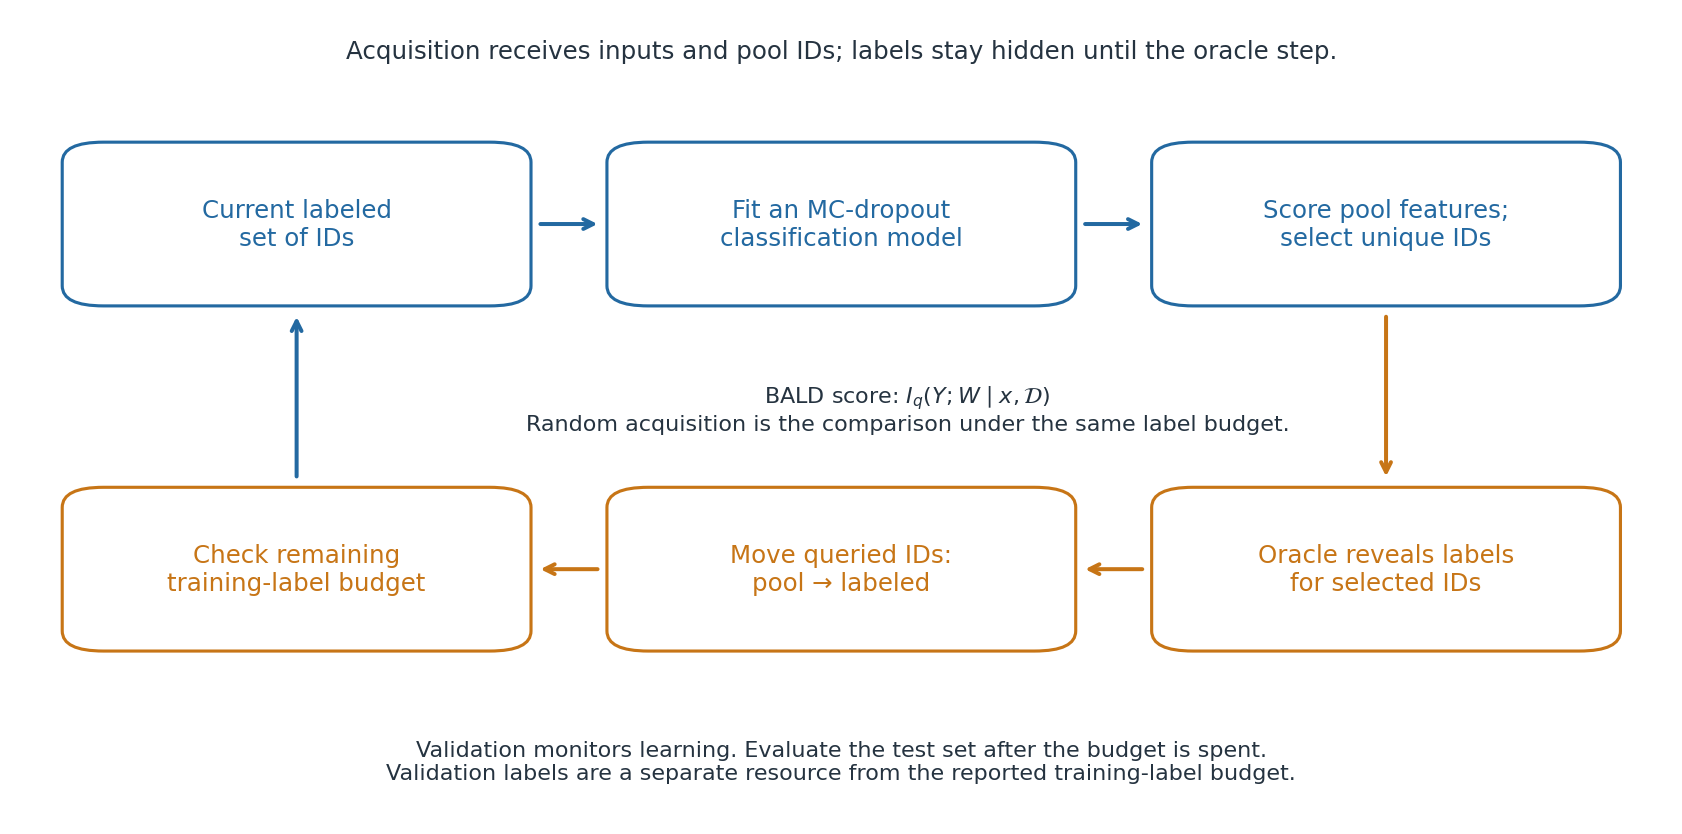

Score pool inputs before asking for labels. The oracle reveals labels only after unique IDs have been selected. Initial labels count towards the same budget; evaluation labels are a separate resource.


## Task 3 — Acquire labels without looking at them

Implement `acquisition_indices(pool_ids, draws, n_query, strategy, generator)`.
`pool_ids` is a CPU integer vector of unique global IDs, and `draws` contains
`(T,N,C)` probabilities in exactly that pool order. Return unique global IDs,
not positions inside the remaining pool.

1. For `random`, sample without replacement using the supplied generator.
2. For `entropy`, select the largest predictive entropies.
3. For `bald`, select the largest mutual informations. Break score ties by
   choosing the smaller global ID first.

The supplied oracle checks for repeated queries and budget overruns. Its
private labels model information access; this Python class is a teaching
interface, not a security boundary. Explain why repeating an index wastes
budget and why querying a top-scoring batch need not maximize joint information.


In [10]:
class LabelOracle:
    def __init__(self, inputs, hidden_labels, budget):
        self.inputs = inputs.clone()
        self._hidden_labels = hidden_labels.clone()
        self.budget = budget
        self._labelled = {}

    @property
    def remaining_ids(self):
        return torch.tensor(
            [i for i in range(len(self.inputs)) if i not in self._labelled], dtype=torch.long
        )

    @property
    def spent(self):
        return len(self._labelled)

    def query(self, ids):
        ids = torch.as_tensor(ids)
        if ids.dtype not in (torch.int32, torch.int64):
            raise ValueError("Oracle IDs must be integers, not floats or booleans")
        ids = ids.to(dtype=torch.long, device="cpu")
        if ids.ndim != 1 or len(torch.unique(ids)) != len(ids):
            raise ValueError("A query must be a vector of unique IDs")
        values = ids.tolist()
        if any(i < 0 or i >= len(self.inputs) or i in self._labelled for i in values):
            raise ValueError("Query contains an invalid or already labelled ID")
        if self.spent + len(values) > self.budget:
            raise ValueError("Query would exceed the total label budget")
        labels = self._hidden_labels[ids].clone()
        for i, label in zip(values, labels.tolist()):
            self._labelled[i] = label
        return ids, labels

    def labelled_data(self):
        ids = torch.tensor(list(self._labelled), dtype=torch.long)
        labels = torch.tensor(list(self._labelled.values()), dtype=torch.long)
        return self.inputs[ids], labels


In [11]:
def acquisition_indices(pool_ids, draws, n_query, strategy="bald", generator=None):
    """Select unique global IDs; no oracle or labels are accepted as arguments."""
    if pool_ids.ndim != 1 or pool_ids.dtype != torch.long or pool_ids.device.type != "cpu":
        raise ValueError("pool_ids must be a CPU int64 vector")
    if draws.ndim != 3 or draws.shape[1] != len(pool_ids) or draws.device.type != "cpu":
        raise ValueError("Expected CPU draws (T,N,C) matching the pool")
    if len(pool_ids.unique()) != len(pool_ids) or not 0 <= n_query <= len(pool_ids):
        raise ValueError("IDs must be unique and the query must fit inside the pool")
    if strategy not in ("random", "entropy", "bald"):
        raise ValueError("Unknown strategy")

    if strategy == "random":
        return pool_ids[torch.randperm(len(pool_ids), generator=generator)[:n_query]]
    terms = uncertainty_terms(draws)
    key = "predictive_entropy" if strategy == "entropy" else "mutual_information"
    by_id = torch.argsort(pool_ids)
    by_score = torch.argsort(terms[key][by_id], descending=True, stable=True)
    return pool_ids[by_id[by_score[:n_query]]]


In [12]:
def test_acquisition():
    if not ready(2):
        raise NotImplementedError("Task 2 prerequisite")
    ids = torch.tensor([41, 7, 99])
    draws = torch.tensor(
        [
            [[0.5, 0.5], [1.0, 0.0], [0.9, 0.1]],
            [[0.5, 0.5], [1.0, 0.0], [0.9, 0.1]],
            [[0.5, 0.5], [1.0, 0.0], [0.9, 0.1]],
            [[0.5, 0.5], [0.0, 1.0], [0.9, 0.1]],
        ],
        dtype=torch.float64,
    )
    assert acquisition_indices(ids, draws, 1, "entropy").tolist() == [41]
    assert acquisition_indices(ids, draws, 1, "bald").tolist() == [7]
    assert acquisition_indices(ids, draws, 3, "bald").tolist() == [7, 41, 99]
    assert len(acquisition_indices(ids, draws, 0)) == 0
    tied = torch.full((4, 3, 2), 0.5, dtype=torch.float64)
    assert acquisition_indices(ids, tied, 3, "entropy").tolist() == [7, 41, 99]
    rng1, rng2 = torch.Generator().manual_seed(10), torch.Generator().manual_seed(10)
    random_ids = acquisition_indices(ids, draws, 3, "random", rng1)
    assert random_ids.unique().numel() == 3
    assert torch.equal(random_ids, ids[torch.randperm(3, generator=rng2)])
    oracle = LabelOracle(torch.arange(5.0)[:, None], torch.tensor([0, 1, 0, 1, 0]), budget=3)
    queried, labels = oracle.query(torch.tensor([3, 1]))
    assert queried.tolist() == [3, 1] and labels.tolist() == [1, 1] and oracle.spent == 2
    assert oracle.remaining_ids.tolist() == [0, 2, 4]
    for invalid in [
        torch.tensor([0, 0]),
        torch.tensor([1]),
        torch.tensor([0, 2]),
        torch.tensor([0.9]),
        torch.tensor([False]),
    ]:
        before = oracle.spent
        try:
            oracle.query(invalid)
        except ValueError:
            pass
        else:
            raise AssertionError("Invalid query accepted")
        assert oracle.spent == before  # Rejections must not mutate the state.


check_task(3, test_acquisition)


Task 3: checks passed.


True

### A controlled one-dimensional comparison

Reuse the same 120 inputs as a finite acquisition pool, now pretending that
their labels have not yet been purchased. Each repeat starts with 12 random
IDs, chosen without labels. Acquire six new labels on each of four rounds,
ending at 36 labels including the initial 12. Random, entropy, and BALD use
the same initial IDs within each repeat.

For this repeated small-data experiment, use a supplied `1 → 32 → 32 → 2`
tanh network, with dropout 0.2 after its first hidden layer and input scaling
$x/5$. It is shared by all acquisition strategies. This simpler network fits
the initially labelled subset more reliably than the deep sigmoid network;
the original architecture in Tasks 1–2 remains the reused example.

At each budget, retrain a fresh network for 1,000 full-batch optimizer steps,
using Adam, weight decay $10^{-4}$, and a OneCycle maximum learning rate 0.03.
Initialization and stochastic-training seeds agree across strategies at the
same round and repeat. Acquisition and evaluation use 64 MC draws. The
training budget and final label count are fixed before results are inspected.
The fixed weight decay on a mean training loss is an optimization convention;
its equivalent penalty on a summed loss grows with the label count. This
comparison does not trace exact Bayesian updates under one fixed prior.

For evaluation only, define a separate population: choose one of the four
intervals uniformly, then sample an input uniformly within that interval and
use its class. This is distinct from the deterministic training grid and is
not globally uniform in $x$. Generate 512 validation and 1,024 final-test
observations. Their evaluation labels are a separate benchmark resource,
outside the 36 acquired training labels. Validation curves do not select
hyperparameters or stopping times; the final test is evaluated after all
acquisition runs finish.


In [13]:
def sample_interval_population(n, seed, end_points=END_POINTS):
    components = [
        (label, left, right) for label, ranges in end_points.items() for left, right in ranges
    ]
    rng = torch.Generator().manual_seed(seed)
    indices = torch.randint(len(components), (n,), generator=rng)
    u = torch.rand(n, generator=rng)
    x, y = torch.empty(n, 1), torch.empty(n, dtype=torch.long)
    for k, (label, left, right) in enumerate(components):
        chosen = indices == k
        x[chosen, 0] = left + (right - left) * u[chosen]
        y[chosen] = label
    return x, y


def classification_metrics(probabilities, labels):
    correct = (probabilities.argmax(-1) == labels).float().mean().item()
    true_p = probabilities[torch.arange(len(labels)), labels]
    nll = -true_p.clamp_min(torch.finfo(probabilities.dtype).tiny).log().mean().item()
    one_hot = torch.nn.functional.one_hot(labels, probabilities.shape[1]).to(
        probabilities.dtype
    )
    brier = (probabilities - one_hot).square().sum(-1).mean().item()
    return {"accuracy": correct, "nll": nll, "brier": brier}


def run_toy_active_learning():
    validation_x, validation_y = sample_interval_population(512, 31)
    test_x, test_y = sample_interval_population(1024, 32)
    records, final_models, initial_ids_by_repeat = [], [], []
    for repeat in range(3):
        initial = torch.randperm(
            len(x_train), generator=torch.Generator().manual_seed(100 + repeat)
        )[:12]
        initial_ids_by_repeat.append(initial)
        for strategy in ["random", "entropy", "bald"]:
            oracle = LabelOracle(x_train, y_train, budget=36)
            oracle.query(initial)
            query_rng = torch.Generator().manual_seed(200 + repeat)
            for round_index in range(5):
                labelled_x, labelled_y = oracle.labelled_data()
                model, _ = fit_toy(
                    labelled_x,
                    labelled_y,
                    seed=1000 + 100 * repeat + round_index,
                    steps=TOY_AL_STEPS,
                    active=True,
                )
                torch.manual_seed(2000 + 100 * repeat + round_index)
                val_probability = mc_probabilities(model, validation_x, 64).mean(0)
                row = {
                    "repeat": repeat,
                    "strategy": strategy,
                    "budget": oracle.spent,
                    **classification_metrics(val_probability, validation_y),
                }
                records.append(row)
                if round_index == 4:
                    final_models.append((repeat, strategy, model, oracle))
                    break
                remaining = oracle.remaining_ids
                torch.manual_seed(3000 + 100 * repeat + round_index)
                draws = mc_probabilities(model, x_train[remaining], 64)
                selected_ids = acquisition_indices(remaining, draws, 6, strategy, query_rng)
                oracle.query(selected_ids)
            assert oracle.spent == 36
    # Keep test evaluation outside every acquisition loop.
    final_results = []
    for repeat, strategy, model, oracle in final_models:
        torch.manual_seed(4000 + repeat)
        probability = mc_probabilities(model, test_x, 256).mean(0)
        _, labels = oracle.labelled_data()
        final_results.append(
            {
                "repeat": repeat,
                "strategy": strategy,
                "class_counts": torch.bincount(labels, minlength=2),
                **classification_metrics(probability, test_y),
            }
        )
    return records, final_results, initial_ids_by_repeat


if ready(1, 2, 3):
    started = time.perf_counter()
    toy_al_records, toy_al_final, toy_initial_ids = run_toy_active_learning()
    print(f"Paired toy experiments completed in {time.perf_counter()-started:.1f} seconds.")
    rows = []
    for strategy in ["random", "entropy", "bald"]:
        results = [r for r in toy_al_final if r["strategy"] == strategy]
        accuracy = np.array([r["accuracy"] for r in results])
        rows.append(
            [
                strategy,
                accuracy.mean(),
                accuracy.std(ddof=1),
                np.mean([r["nll"] for r in results]),
                np.mean([r["brier"] for r in results]),
            ]
        )
    table(["Strategy", "Final test accuracy", "Repeat SD", "Test NLL", "Test Brier"], rows)


Paired toy experiments completed in 33.7 seconds.


| Strategy | Final test accuracy | Repeat SD | Test NLL | Test Brier |
| --- | --- | --- | --- | --- |
| random | 0.98145 | 0.0060986 | 0.0384 | 0.024007 |
| entropy | 0.83301 | 0.14208 | 1.2146 | 0.33598 |
| bald | 0.83236 | 0.14265 | 1.1467 | 0.3357 |

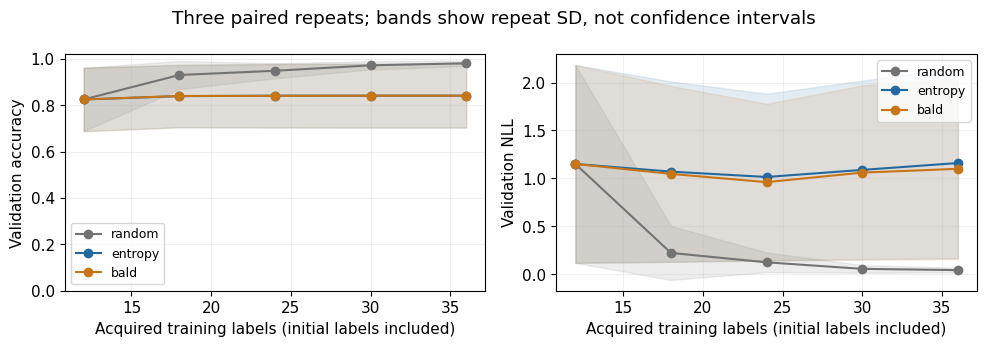

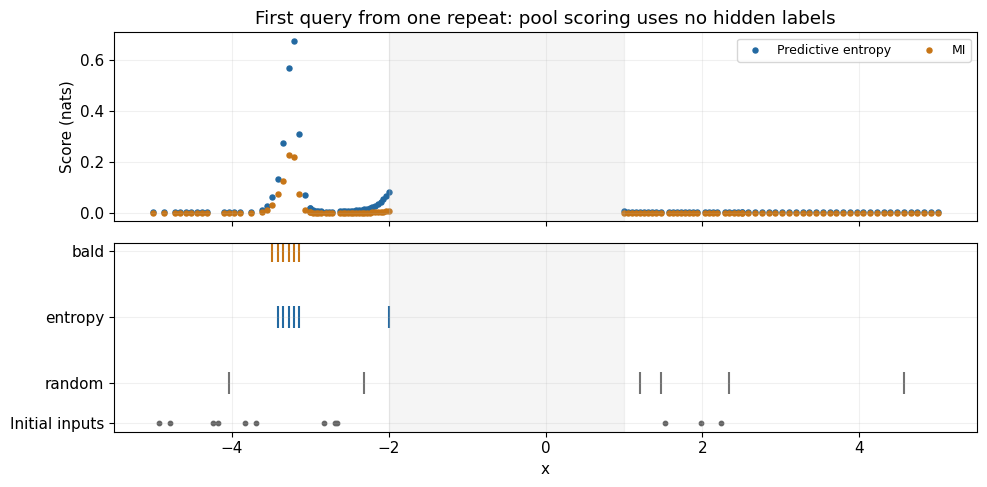

In [14]:
if ready(1, 2, 3):
    budgets = [12, 18, 24, 30, 36]
    colors = {"random": "0.45", "entropy": BLUE, "bald": ORANGE}
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for strategy in ["random", "entropy", "bald"]:
        for ax, metric in zip(axes, ["accuracy", "nll"]):
            values = np.array(
                [
                    [
                        next(
                            r[metric]
                            for r in toy_al_records
                            if r["strategy"] == strategy
                            and r["repeat"] == rep
                            and r["budget"] == budget
                        )
                        for budget in budgets
                    ]
                    for rep in range(3)
                ]
            )
            mean, sd = values.mean(0), values.std(0, ddof=1)
            ax.plot(budgets, mean, marker="o", color=colors[strategy], label=strategy)
            ax.fill_between(budgets, mean - sd, mean + sd, color=colors[strategy], alpha=0.12)
    axes[0].set(
        xlabel="Acquired training labels (initial labels included)",
        ylabel="Validation accuracy",
        ylim=(0, 1.02),
    )
    axes[1].set(
        xlabel="Acquired training labels (initial labels included)", ylabel="Validation NLL"
    )
    for ax in axes:
        ax.legend(fontsize=9)
    fig.suptitle("Three paired repeats; bands show repeat SD, not confidence intervals")
    plt.tight_layout()
    show_figure(fig, "toy_learning_curves")

    # Show a single, explicitly labelled acquisition decision before querying.
    oracle = LabelOracle(x_train, y_train, budget=18)
    oracle.query(toy_initial_ids[0])
    x_labelled, y_labelled = oracle.labelled_data()
    initial_model, _ = fit_toy(
        x_labelled, y_labelled, seed=1000, steps=TOY_AL_STEPS, active=True
    )
    pool_ids = oracle.remaining_ids
    torch.manual_seed(3000)
    pool_draws = mc_probabilities(initial_model, x_train[pool_ids], 64)
    pool_scores = uncertainty_terms(pool_draws)
    fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
    axes[0].scatter(
        x_train[pool_ids, 0],
        pool_scores["predictive_entropy"],
        s=13,
        color=BLUE,
        label="Predictive entropy",
    )
    axes[0].scatter(
        x_train[pool_ids, 0], pool_scores["mutual_information"], s=13, color=ORANGE, label="MI"
    )
    axes[0].set(
        ylabel="Score (nats)",
        title="First query from one repeat: pool scoring uses no hidden labels",
    )
    for j, strategy in enumerate(["random", "entropy", "bald"]):
        chosen = acquisition_indices(
            pool_ids, pool_draws, 6, strategy, torch.Generator().manual_seed(200)
        )
        axes[1].scatter(
            x_train[chosen, 0],
            np.full(len(chosen), j),
            marker="|",
            s=250,
            color=colors[strategy],
            label=strategy,
        )
    axes[1].scatter(x_labelled[:, 0], np.full(len(x_labelled), -0.6), s=10, color="0.4")
    axes[1].set(
        xlabel="x",
        yticks=[-0.6, 0, 1, 2],
        yticklabels=["Initial inputs", "random", "entropy", "bald"],
    )
    for ax in axes:
        ax.axvspan(-2, 1, color="0.7", alpha=0.13)
    axes[0].legend(ncol=2, fontsize=9)
    plt.tight_layout()
    show_figure(fig, "toy_acquisition")


Interpretation questions. Compare final test scores and the spread across
repeats. Did one strategy improve every criterion on every seed? Where do
the first queried inputs lie? What information can an acquisition rule use,
and which labels count towards the reported budget?


Interpretation. Compare like-for-like budgets, including the initial 12 labels, and describe
the actual repeated results. The acquisition rule can inspect pool features
and predictions, but hidden labels become available only after querying.
Validation and test labels are a separate evaluation resource in this
simulation. Closely spaced high-score inputs can be redundant, and unstable
dropout approximations or refitting can change a ranking. An average advantage
on three repeats is evidence for this setting, not a universal guarantee that
BALD dominates random or entropy acquisition.


## Task 4 — Buy labels for handwritten digits

The one-dimensional experiment made the acquisition rule visible. Now use a
small dropout CNN on MNIST and compare three ways to spend the same label
budget: uniform random sampling, predictive entropy, and BALD.

Your task is to implement the Monte Carlo prediction routine used both for
acquisition and evaluation. The model, label oracle, training loop and plots
are supplied. Complete the CPU checks first. With `RUN_MNIST=True`, an
available CUDA device then enables the experiment; earlier tasks remain on
the CPU. The default experiment uses three paired repeats and usually takes
a few minutes on a recent GPU. Changing the budget is an experimental
decision: choose it before looking at the curves or test results.

### 6.1 What is compared?

Each repeat starts from the same 6,000 unlabelled training images and the
same 100 uniformly sampled labelled images for all three strategies. We
acquire 100 more labels at a time, ending with 500. Pool construction and
initial selection never inspect class labels. An oracle exposes labels only
for requested pool indices. All 100 initial labels count towards the budget.

At each budget we reset the CNN to the same seeded initialization and use
150 Adam updates with the same batch size and learning rate. The methods
therefore have equal training budgets, including the random control.
Acquisition computation is additional work for entropy and BALD. We select
the 100 largest pointwise scores without any batch-diversity correction;
several selected digits can be redundant. This is ordinary batch BALD
selection, not the joint-information method BatchBALD.

A separate, fixed set of 1,000 training images supplies evaluation labels
for the learning curves. These labels are a separate evaluation resource,
not part of the acquisition budget and never passed to fitting or selection.
The curves do not change the fixed stopping rule or hyperparameters. The
official test set is evaluated only after all acquisition runs finish.
BALD is not guaranteed to beat random sampling on a particular seed or at
this small compute budget.

### 6.2 Dropout at prediction time

`model.train()` would also update batch-normalization statistics if the
architecture contained batch normalization. Instead, the supplied context
manager evaluates the model, activates only dropout modules, and restores
every module's previous mode afterwards.

Return probabilities with shape `(T,N,10)`: Monte Carlo draw, image, class.
For classification, average probabilities, not logits. Standard PyTorch
dropout gives independent masks to different images. That suffices for
each image's marginal entropy and mutual information; a row of this tensor
is not a coherent function draw across images or input minibatches. The
one-dimensional plots used a shared mask for that different purpose.


In [15]:
from contextlib import contextmanager
from pathlib import Path
import copy
import os
import time

MNIST_POOL_SIZE = 6_000
MNIST_VALIDATION_SIZE = 1_000
MNIST_INITIAL_LABELS = 100
MNIST_QUERY_SIZE = 100
MNIST_ACQUISITIONS = 4
MNIST_REPEATS = 3
MNIST_TRAIN_UPDATES = 150
MNIST_BATCH_SIZE = 64
MNIST_MC_DRAWS = 15
MNIST_RETRAIN = True
MNIST_DATA = Path(os.environ.get("BNN_MNIST_DATA", "/tmp/sk_bayes_mnist/data"))
MNIST_CACHE = Path(os.environ.get("BNN_MNIST_CACHE", "/tmp/sk_bayes_bnn_mnist"))
MNIST_STRATEGIES = ("random", "entropy", "bald")
MNIST_COLORS = {"random": "#787878", "entropy": "#d58b27", "bald": "#267b9e"}
mnist_enabled = False


@contextmanager
def mnist_dropout_only(model):
    """Enable only dropout and restore all module modes, also after errors."""
    previous = [(module, module.training) for module in model.modules()]
    try:
        model.eval()
        for module in model.modules():
            if isinstance(module, (nn.Dropout, nn.Dropout1d, nn.Dropout2d, nn.Dropout3d)):
                module.train()
        yield
    finally:
        for module, training in previous:
            module.training = training


def mnist_inputs(images, device):
    """Integer pixels -> standard MNIST normalization on the requested device."""
    return (images.to(device=device, dtype=torch.float32) / 255.0 - 0.1307) / 0.3081


def mnist_show_figure(figure, name):
    """Optional print-quality copies for the teacher's guide."""
    if globals().get("SAVE_FIGURES", False):
        destination = Path("assets")
        destination.mkdir(parents=True, exist_ok=True)
        figure.savefig(destination / name, bbox_inches="tight")
    plt.show()


Complete `mc_cnn_probabilities`.

1. Inside `torch.inference_mode()` and `mnist_dropout_only(model)`, repeat
   prediction `n_draws` times.
2. For each draw, process all images in minibatches using `mnist_inputs`.
   Apply `softmax` over the class axis of the model's logits.
3. Concatenate image minibatches in their original order and stack draws.
   Return a CPU float32 tensor of shape `(n_draws,N,10)`, with no gradient
   history. Neither the model's modes nor batch-normalization statistics
   should change. Use the device of the model's first parameter.

The supplied argument checks also prevent an empty list of minibatches.


In [16]:
def mc_cnn_probabilities(model, images, n_draws=15, batch_size=512):
    """Predict probabilities: uint8 (N,1,28,28) -> CPU float32 (T,N,10)."""
    if n_draws < 1 or batch_size < 1 or len(images) == 0:
        raise ValueError("Use positive draws, positive batch size, and nonempty images.")
    device = next(model.parameters()).device
    draws = []
    with torch.inference_mode(), mnist_dropout_only(model):
        for _ in range(n_draws):
            batches = []
            for start in range(0, len(images), batch_size):
                x = mnist_inputs(images[start : start + batch_size], device)
                batches.append(model(x).softmax(dim=-1).float().cpu())
            draws.append(torch.cat(batches, dim=0))
    return torch.stack(draws, dim=0)


In [17]:
def test_mnist_mc_prediction():
    class Probe(nn.Module):
        def __init__(self, dropout):
            super().__init__()
            self.bn = nn.BatchNorm2d(1)
            self.dropout = nn.Dropout(dropout)
            self.linear = nn.Linear(28 * 28, 10)

        def forward(self, x):
            return self.linear(self.dropout(self.bn(x).flatten(1)))

    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(42)
        images = torch.randint(0, 256, (9, 1, 28, 28), dtype=torch.uint8)
        deterministic = Probe(0.0).float()
        deterministic.eval()
        with torch.no_grad():
            deterministic.linear.weight.zero_()
            deterministic.linear.bias.copy_(torch.linspace(-1, 1, 10, dtype=torch.float32))
        expected = torch.softmax(torch.linspace(-1, 1, 10, dtype=torch.float32), dim=-1)
        probabilities = mc_cnn_probabilities(deterministic, images, 3, 4)
        torch.testing.assert_close(probabilities, expected.expand(3, 9, 10))
        assert probabilities.dtype == torch.float32 and probabilities.device.type == "cpu"
        assert not probabilities.requires_grad

        class PixelProbe(nn.Module):
            def __init__(self):
                super().__init__()
                self.anchor = nn.Parameter(torch.tensor(0.0, dtype=torch.float32))

            def forward(self, x):
                return x.flatten(1)[:, :10] + self.anchor

        # Input-sensitive oracle checks scaling and minibatch order independently.
        expected_pixels = ((images.float() / 255.0 - 0.1307) / 0.3081).flatten(1)
        expected_pixels = expected_pixels[:, :10].softmax(-1)
        ordered = mc_cnn_probabilities(PixelProbe(), images, 3, 4)
        torch.testing.assert_close(ordered, expected_pixels.expand(3, 9, 10))

        stochastic = Probe(0.5).float()
        stochastic.train()
        stochastic.bn.eval()  # Deliberately mixed modes must also be restored.
        before_modes = [module.training for module in stochastic.modules()]
        before_mean = stochastic.bn.running_mean.clone()
        before_var = stochastic.bn.running_var.clone()
        draws = mc_cnn_probabilities(stochastic, images, 8, 4)
        assert draws.shape == (8, 9, 10)
        assert torch.isfinite(draws).all() and (draws >= 0).all()
        torch.testing.assert_close(draws.sum(-1), torch.ones(8, 9, dtype=torch.float32))
        assert draws.var(dim=0).max() > 1e-5, "Dropout must remain stochastic."
        assert before_modes == [module.training for module in stochastic.modules()]
        torch.testing.assert_close(stochastic.bn.running_mean, before_mean)
        torch.testing.assert_close(stochastic.bn.running_var, before_var)

        try:
            with mnist_dropout_only(stochastic):
                raise RuntimeError("Check restoration on an interrupted prediction.")
        except RuntimeError:
            pass
        assert before_modes == [module.training for module in stochastic.modules()]


mnist_task_ready = False
try:
    test_mnist_mc_prediction()
    mnist_task_ready = True
    print("Task 4 CPU checks passed: probabilities, stochastic dropout, and mode restoration.")
except NotImplementedError:
    print("Complete Task 4 to enable the GPU experiment.")


Task 4 CPU checks passed: probabilities, stochastic dropout, and mode restoration.


Interpretation. The class probabilities must sum to one for each draw and image. If dropout
is disabled, all draws coincide and the mutual-information estimate is zero.
If logits are averaged before softmax, the resulting distribution is not the
Monte Carlo approximation to the posterior predictive. Restoring module
modes matters when this helper is called from a training notebook.


### 6.3 A fixed-budget experiment

The first enabled run downloads MNIST through
[`torchvision.datasets.MNIST`](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html).
The default data cache is shared with the normalizing-flow seminar; results
and fitted checkpoints are saved separately under `/tmp/sk_bayes_bnn_mnist`.
Set `BNN_MNIST_DATA` and `BNN_MNIST_CACHE` before running the notebook to
choose persistent locations. `MNIST_RETRAIN=True` fits on every enabled run;
set it to `False` to replay a matching completed experiment.

The following implementation is supplied. Notice that the acquisition
function receives images and pool indices, never a vector of hidden labels.
The oracle is a teaching interface, not a security boundary: it represents
the information a real annotator would reveal after a query.


In [18]:
class MnistDropoutCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class MnistLabelOracle:
    def __init__(self, hidden_labels):
        self._hidden_labels = hidden_labels.clone().cpu()
        self.queried = set()

    def query(self, pool_ids):
        requested = torch.as_tensor(pool_ids)
        if requested.ndim != 1 or requested.dtype not in (torch.int32, torch.int64):
            raise ValueError("Oracle IDs must be an integer vector, not floats or booleans.")
        ids = requested.to(device="cpu", dtype=torch.long).tolist()
        if len(ids) != len(set(ids)) or any(index in self.queried for index in ids):
            raise ValueError("Every new label must be queried exactly once.")
        if any(index < 0 or index >= len(self._hidden_labels) for index in ids):
            raise IndexError("Pool index outside the oracle's collection.")
        self.queried.update(ids)
        return self._hidden_labels[torch.tensor(ids, dtype=torch.long)]


def test_mnist_oracle_ids():
    oracle = MnistLabelOracle(torch.tensor([2, 4, 6]))
    for invalid in [[0.9], [False], [1, 1], [3]]:
        try:
            oracle.query(invalid)
        except (ValueError, IndexError):
            pass
        else:
            raise AssertionError("Oracle accepted an invalid ID request")
        assert not oracle.queried
    assert oracle.query([2, 0]).tolist() == [6, 2]


test_mnist_oracle_ids()


def mnist_uncertainty(draws):
    """Pointwise (predictive entropy, expected entropy, BALD), in nats."""
    probabilities = draws.clamp_min(torch.finfo(draws.dtype).tiny)
    mean = probabilities.mean(dim=0)
    predictive = -(mean * mean.log()).sum(dim=-1)
    expected = -(probabilities * probabilities.log()).sum(dim=-1).mean(dim=0)
    return predictive, expected, (predictive - expected).clamp_min(0)


def mnist_metrics(mean_probabilities, labels):
    labels = labels.cpu()
    probabilities = mean_probabilities.cpu().clamp_min(1e-12)
    confidence, prediction = probabilities.max(dim=-1)
    correct = prediction.eq(labels).float()
    nll = -probabilities[torch.arange(len(labels)), labels].log().mean()
    ece = torch.tensor(0.0)
    edges = torch.linspace(0, 1, 16)
    for lower, upper in zip(edges[:-1], edges[1:]):
        inside = (confidence > lower) & (confidence <= upper)
        if inside.any():
            ece += (
                inside.float().mean()
                * (correct[inside].mean() - confidence[inside].mean()).abs()
            )
    return {"accuracy": float(correct.mean()), "nll": float(nll), "ece": float(ece)}


def mnist_fit(pool_inputs, labelled_ids, labelled_values, seed):
    """Fresh seeded initialization; the same number of optimizer updates."""
    torch.manual_seed(seed)
    model = MnistDropoutCNN().float().to(pool_inputs.device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    x = pool_inputs[torch.as_tensor(labelled_ids, device=pool_inputs.device)]
    y = labelled_values.to(pool_inputs.device)
    model.train()
    for _ in range(MNIST_TRAIN_UPDATES):
        batch = torch.randint(len(x), (MNIST_BATCH_SIZE,), device=x.device)
        optimizer.zero_grad(set_to_none=True)
        loss = torch.nn.functional.cross_entropy(model(x[batch]), y[batch])
        loss.backward()
        optimizer.step()
    return model


def mnist_run_active_learning(
    pool_images, hidden_labels, validation_images, validation_labels, device
):
    pool_inputs = mnist_inputs(pool_images, device)
    runs = []
    for repeat in range(MNIST_REPEATS):
        initial_generator = torch.Generator().manual_seed(18_000 + repeat)
        initial = torch.randperm(len(pool_images), generator=initial_generator)[
            :MNIST_INITIAL_LABELS
        ]
        for strategy in MNIST_STRATEGIES:
            oracle = MnistLabelOracle(hidden_labels)
            labelled_ids = initial.tolist()
            labelled_values = oracle.query(labelled_ids)
            random_generator = torch.Generator().manual_seed(28_000 + repeat)
            history, acquisitions = [], []
            first_diagnostic = None
            model = None
            for round_index in range(MNIST_ACQUISITIONS + 1):
                seed = 38_000 + 100 * repeat + round_index
                model = mnist_fit(pool_inputs, labelled_ids, labelled_values, seed)
                torch.manual_seed(seed + 100_000)
                validation_draws = mc_cnn_probabilities(
                    model, validation_images, MNIST_MC_DRAWS
                )
                metrics = mnist_metrics(validation_draws.mean(0), validation_labels)
                history.append({"labels": len(labelled_ids), **metrics})
                print(
                    f"repeat {repeat + 1}/{MNIST_REPEATS} | {strategy:7s} | "
                    f"labels {len(labelled_ids):3d} | validation accuracy "
                    f"{metrics['accuracy']:.3f}"
                )
                if round_index == MNIST_ACQUISITIONS:
                    break

                labelled_mask = torch.zeros(len(pool_images), dtype=torch.bool)
                labelled_mask[labelled_ids] = True
                candidates = torch.arange(len(pool_images))[~labelled_mask]
                n_query = min(MNIST_QUERY_SIZE, len(candidates))
                if strategy == "random":
                    local_selection = torch.randperm(
                        len(candidates), generator=random_generator
                    )[:n_query]
                    scores = None
                else:
                    torch.manual_seed(seed + 200_000)
                    candidate_draws = mc_cnn_probabilities(
                        model, pool_images[candidates], MNIST_MC_DRAWS
                    )
                    predictive, expected, information = mnist_uncertainty(candidate_draws)
                    scores = predictive if strategy == "entropy" else information
                    # Stable sorting makes equal-score ties reproducible.
                    local_selection = torch.argsort(scores, descending=True, stable=True)[
                        :n_query
                    ]
                    if repeat == 0 and round_index == 0 and strategy == "bald":
                        first_diagnostic = {
                            "pool_ids": candidates.clone(),
                            "predictive": predictive.clone(),
                            "expected": expected.clone(),
                            "information": information.clone(),
                            "probabilities": candidate_draws.mean(0),
                            "selected_local": local_selection.clone(),
                        }
                selected = candidates[local_selection]
                # The first and only label lookup for these selected examples.
                revealed = oracle.query(selected.tolist())
                acquisitions.append(
                    {
                        "pool_ids": selected.clone(),
                        "labels": revealed.clone(),
                        "scores": None if scores is None else scores[local_selection].clone(),
                    }
                )
                labelled_ids.extend(selected.tolist())
                labelled_values = torch.cat([labelled_values, revealed])
                assert len(oracle.queried) == len(labelled_ids)
            assert (
                len(labelled_ids)
                == MNIST_INITIAL_LABELS + MNIST_ACQUISITIONS * MNIST_QUERY_SIZE
            )
            runs.append(
                {
                    "repeat": repeat,
                    "strategy": strategy,
                    "history": history,
                    "initial_ids": initial.clone(),
                    "acquisitions": acquisitions,
                    "diagnostic": first_diagnostic,
                    "state_dict": {
                        key: value.detach().cpu() for key, value in model.state_dict().items()
                    },
                }
            )
    # Paired methods must start with exactly the same labels and fit.
    for repeat in range(MNIST_REPEATS):
        paired = [run for run in runs if run["repeat"] == repeat]
        assert all(torch.equal(paired[0]["initial_ids"], run["initial_ids"]) for run in paired)
        assert max(run["history"][0]["accuracy"] for run in paired) == min(
            run["history"][0]["accuracy"] for run in paired
        )
    return runs


In [19]:
mnist_results = None
if not mnist_task_ready:
    print("MNIST experiment skipped: complete Task 4 first.")
elif not globals().get("RUN_MNIST", True):
    print("MNIST experiment disabled by RUN_MNIST=False.")
elif not torch.cuda.is_available():
    print("No CUDA device: CPU checks passed; GPU training is explicitly skipped.")
else:
    from torchvision.datasets import MNIST

    mnist_device = torch.device("cuda")
    print("GPU:", torch.cuda.get_device_name(mnist_device))
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    MNIST_CACHE.mkdir(parents=True, exist_ok=True)
    mnist_configuration = {
        "version": 1,
        "pool": MNIST_POOL_SIZE,
        "validation": MNIST_VALIDATION_SIZE,
        "initial": MNIST_INITIAL_LABELS,
        "query": MNIST_QUERY_SIZE,
        "acquisitions": MNIST_ACQUISITIONS,
        "repeats": MNIST_REPEATS,
        "updates": MNIST_TRAIN_UPDATES,
        "batch": MNIST_BATCH_SIZE,
        "draws": MNIST_MC_DRAWS,
    }
    mnist_checkpoint = MNIST_CACHE / "bnn_mnist_active_learning.pt"
    training_data = MNIST(str(MNIST_DATA), train=True, download=True)
    partition_generator = torch.Generator().manual_seed(7_026)
    partition = torch.randperm(len(training_data), generator=partition_generator)
    pool_ids = partition[:MNIST_POOL_SIZE]
    validation_ids = partition[MNIST_POOL_SIZE : MNIST_POOL_SIZE + MNIST_VALIDATION_SIZE]
    assert len(set(pool_ids.tolist()) & set(validation_ids.tolist())) == 0
    mnist_pool_images = training_data.data[pool_ids, None].clone()
    mnist_validation_images = training_data.data[validation_ids, None].clone()
    mnist_validation_labels = training_data.targets[validation_ids].clone()
    if not MNIST_RETRAIN and mnist_checkpoint.exists():
        cached = torch.load(mnist_checkpoint, map_location="cpu", weights_only=False)
        if cached["configuration"] != mnist_configuration:
            raise ValueError(
                "Cached experiment has a different configuration; set MNIST_RETRAIN=True."
            )
        mnist_results = cached
        print("Loaded completed experiment:", mnist_checkpoint)
    else:
        start = time.perf_counter()
        runs = mnist_run_active_learning(
            mnist_pool_images,
            training_data.targets[pool_ids],
            mnist_validation_images,
            mnist_validation_labels,
            mnist_device,
        )

        # All fits, acquisition choices, and stopping decisions are complete.
        test_data = MNIST(str(MNIST_DATA), train=False, download=True)
        test_images = test_data.data[:, None]
        for run in runs:
            model = MnistDropoutCNN().float().to(mnist_device)
            model.load_state_dict(run["state_dict"])
            torch.manual_seed(500_000 + run["repeat"])
            test_draws = mc_cnn_probabilities(model, test_images, MNIST_MC_DRAWS)
            run["test"] = mnist_metrics(test_draws.mean(0), test_data.targets)
        torch.cuda.synchronize()
        mnist_results = {
            "configuration": mnist_configuration,
            "runs": runs,
            "runtime_seconds": time.perf_counter() - start,
            "gpu": torch.cuda.get_device_name(mnist_device),
        }
        torch.save(mnist_results, mnist_checkpoint)
        print(
            f"Completed in {mnist_results['runtime_seconds']:.1f} seconds; saved {mnist_checkpoint}"
        )
    mnist_enabled = True
    print("Final test metrics, after the fixed acquisition budgets:")
    print("strategy     accuracy (mean ± repeat SD)       NLL       ECE")
    for strategy in MNIST_STRATEGIES:
        selected = [run for run in mnist_results["runs"] if run["strategy"] == strategy]
        accuracies = np.array([run["test"]["accuracy"] for run in selected])
        nll = np.mean([run["test"]["nll"] for run in selected])
        ece = np.mean([run["test"]["ece"] for run in selected])
        print(
            f"{strategy:8s}       {accuracies.mean():.3f} ± {accuracies.std(ddof=1):.3f}"
            f"                 {nll:.3f}     {ece:.3f}"
        )


GPU: NVIDIA L40


repeat 1/3 | random  | labels 100 | validation accuracy 0.839


repeat 1/3 | random  | labels 200 | validation accuracy 0.875


repeat 1/3 | random  | labels 300 | validation accuracy 0.870


repeat 1/3 | random  | labels 400 | validation accuracy 0.910


repeat 1/3 | random  | labels 500 | validation accuracy 0.914


... (37 outputs left out)

repeat 3/3 | bald    | labels 300 | validation accuracy 0.916


repeat 3/3 | bald    | labels 400 | validation accuracy 0.944


repeat 3/3 | bald    | labels 500 | validation accuracy 0.935


Completed in 18.6 seconds; saved /tmp/sk_bayes_bnn_mnist/bnn_mnist_active_learning.pt
Final test metrics, after the fixed acquisition budgets:
strategy     accuracy (mean ± repeat SD)       NLL       ECE
random         0.917 ± 0.003                 0.303     0.057
entropy        0.938 ± 0.014                 0.277     0.107
bald           0.946 ± 0.003                 0.272     0.120


### 6.4 Learning curves and paired outcomes

The bands below show one standard deviation across repeats, not a
confidence interval. With three repeats, treat small differences cautiously.
The connected endpoint dots show the pairing: each line joins strategies
that started with the same labelled images and model seed. Accuracy and log
loss answer different questions; confidence can worsen while accuracy rises.


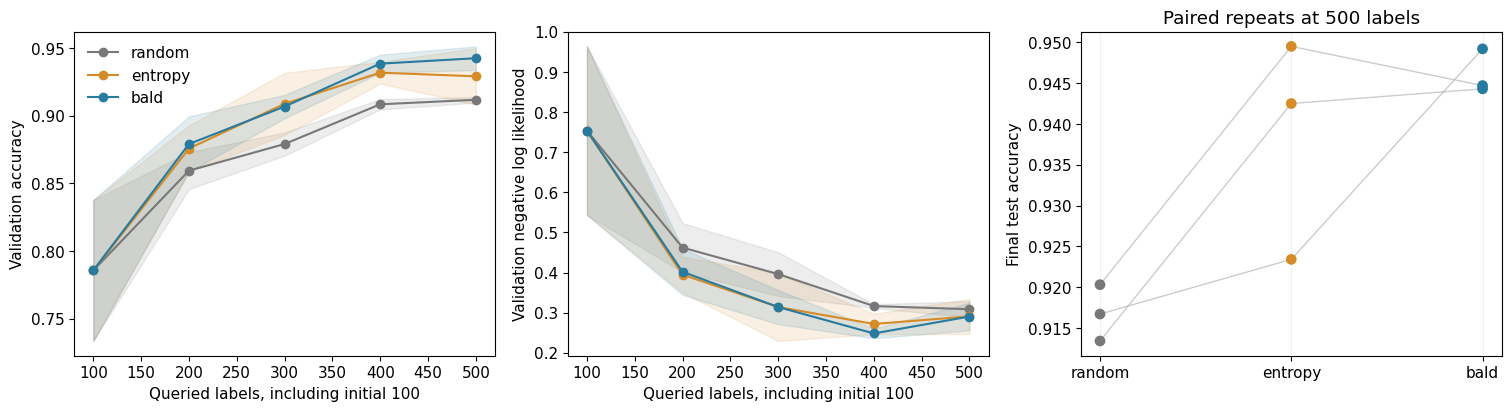

In [20]:
if mnist_enabled:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.0), constrained_layout=True)
    for strategy in MNIST_STRATEGIES:
        selected = [run for run in mnist_results["runs"] if run["strategy"] == strategy]
        budgets = [point["labels"] for point in selected[0]["history"]]
        for ax, metric, label in zip(
            axes[:2],
            ("accuracy", "nll"),
            ("Validation accuracy", "Validation negative log likelihood"),
        ):
            values = np.array(
                [[point[metric] for point in run["history"]] for run in selected]
            )
            mean, spread = values.mean(axis=0), values.std(axis=0, ddof=1)
            ax.plot(budgets, mean, marker="o", color=MNIST_COLORS[strategy], label=strategy)
            ax.fill_between(
                budgets, mean - spread, mean + spread, color=MNIST_COLORS[strategy], alpha=0.13
            )
            ax.set(xlabel="Queried labels, including initial 100", ylabel=label)
            ax.grid(alpha=0.18)
    for repeat in range(MNIST_REPEATS):
        paired = [
            next(
                run
                for run in mnist_results["runs"]
                if run["repeat"] == repeat and run["strategy"] == strategy
            )
            for strategy in MNIST_STRATEGIES
        ]
        endpoints = [run["test"]["accuracy"] for run in paired]
        axes[2].plot(range(3), endpoints, color="#aaaaaa", alpha=0.6, linewidth=1)
        axes[2].scatter(
            range(3),
            endpoints,
            color=[MNIST_COLORS[s] for s in MNIST_STRATEGIES],
            s=45,
            zorder=3,
        )
    axes[0].legend(frameon=False)
    axes[2].set(
        xticks=range(3),
        xticklabels=MNIST_STRATEGIES,
        ylabel="Final test accuracy",
        title="Paired repeats at 500 labels",
    )
    axes[2].grid(axis="y", alpha=0.18)
    mnist_show_figure(fig, "mnist_learning_curves.pdf")


### 6.5 What does BALD buy?

At the first query, the entropy and BALD models are exactly the same fitted
CNN. The scatter separates total predictive uncertainty from disagreement
between dropout predictions. A digit can have high predictive entropy but
relatively small mutual information when the sampled models agree that it
is ambiguous. Both quantities depend on the approximation and fit; they
are not ground-truth labels for two kinds of uncertainty.

The right-hand panel shows the high-BALD batch on top of the full candidate
pool. Selection uses only the score; class labels are revealed afterwards.


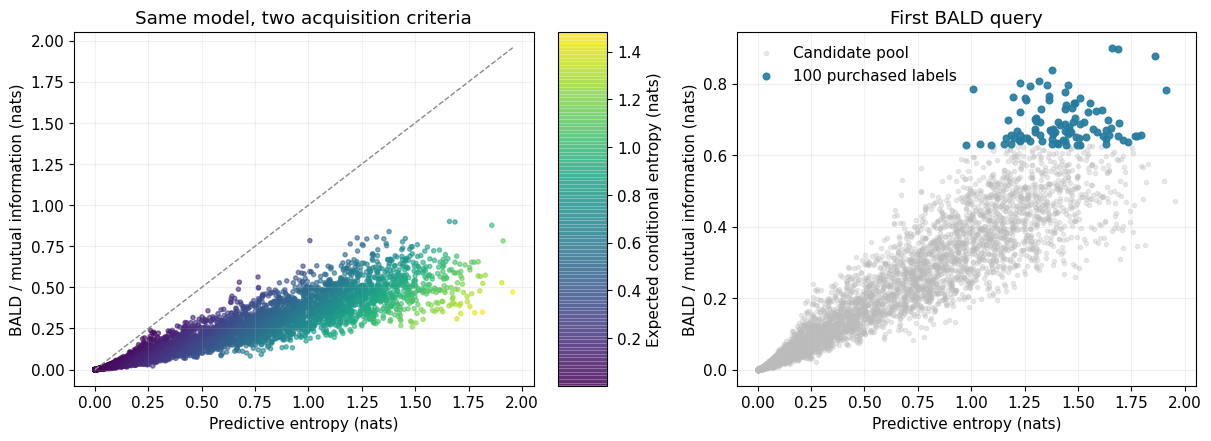

In [21]:
if mnist_enabled:
    diagnostic_run = next(
        run
        for run in mnist_results["runs"]
        if run["repeat"] == 0 and run["strategy"] == "bald"
    )
    diagnostic = diagnostic_run["diagnostic"]
    entropy = diagnostic["predictive"].numpy()
    information = diagnostic["information"].numpy()
    selected = diagnostic["selected_local"].numpy()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), constrained_layout=True)
    expected = diagnostic["expected"].numpy()
    scatter = axes[0].scatter(entropy, information, c=expected, cmap="viridis", s=9, alpha=0.6)
    limit = max(entropy.max(), information.max())
    axes[0].plot([0, limit], [0, limit], color="#888888", linestyle="--", linewidth=1)
    axes[0].set(
        xlabel="Predictive entropy (nats)",
        ylabel="BALD / mutual information (nats)",
        title="Same model, two acquisition criteria",
    )
    fig.colorbar(scatter, ax=axes[0], label="Expected conditional entropy (nats)")
    axes[1].scatter(
        entropy, information, color="#bbbbbb", s=9, alpha=0.3, label="Candidate pool"
    )
    axes[1].scatter(
        entropy[selected],
        information[selected],
        color=MNIST_COLORS["bald"],
        s=23,
        alpha=0.9,
        label="100 purchased labels",
    )
    axes[1].set(
        xlabel="Predictive entropy (nats)",
        ylabel="BALD / mutual information (nats)",
        title="First BALD query",
    )
    axes[1].legend(frameon=False)
    mnist_show_figure(fig, "mnist_uncertainty.pdf")


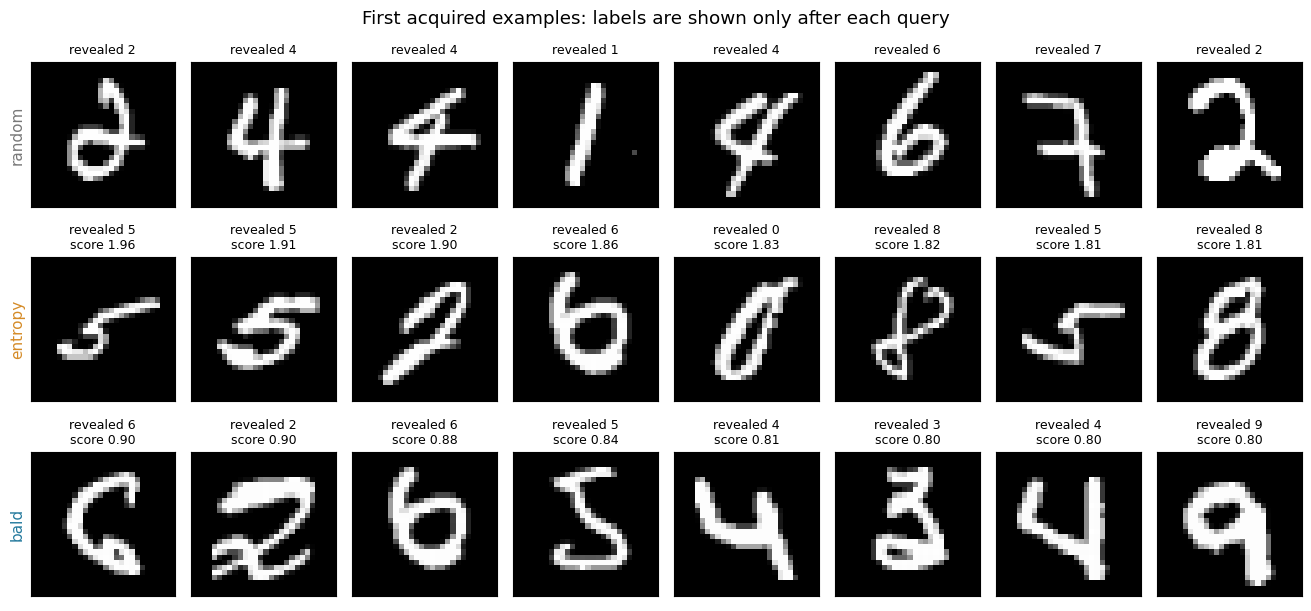

In [22]:
if mnist_enabled:
    fig, axes = plt.subplots(3, 8, figsize=(13, 6), constrained_layout=True)
    for row, strategy in enumerate(MNIST_STRATEGIES):
        run = next(
            run
            for run in mnist_results["runs"]
            if run["repeat"] == 0 and run["strategy"] == strategy
        )
        purchase = run["acquisitions"][0]
        for column, ax in enumerate(axes[row]):
            pool_id = int(purchase["pool_ids"][column])
            ax.imshow(mnist_pool_images[pool_id, 0], cmap="gray", vmin=0, vmax=255)
            label = int(purchase["labels"][column])
            score = purchase["scores"]
            title = f"revealed {label}"
            if score is not None:
                title += f"\nscore {float(score[column]):.2f}"
            ax.set_title(title, fontsize=9)
            ax.set_xticks([])
            ax.set_yticks([])
            if column == 0:
                ax.set_ylabel(strategy, color=MNIST_COLORS[strategy], fontsize=11)
    fig.suptitle("First acquired examples: labels are shown only after each query")
    mnist_show_figure(fig, "mnist_acquired_digits.pdf")


### 6.6 Annotation mix

This diagnostic inspects the labels that have already been purchased. It
does not inspect the remaining pool labels. A changing class mix can expose
redundant queries or a class-specific weakness, but class balance alone is
not an acquisition objective and does not establish which strategy is best.


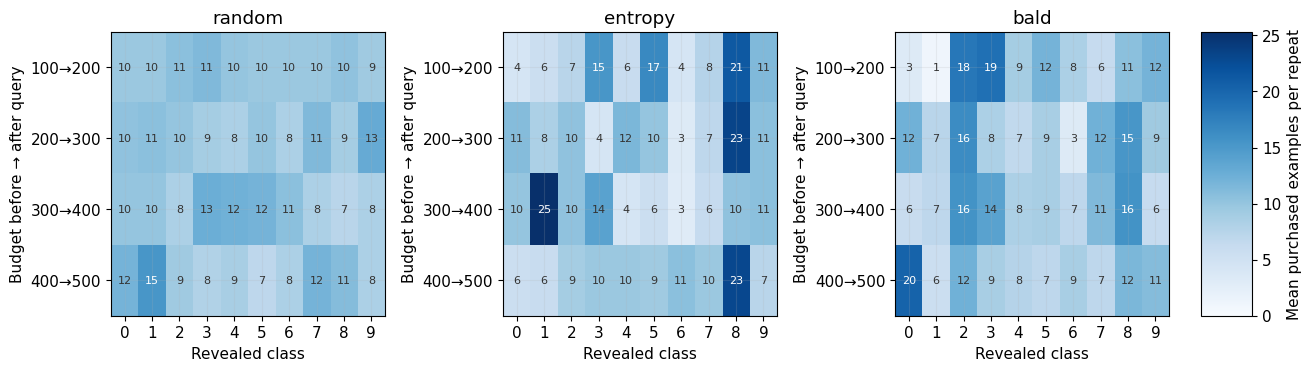

In [23]:
if mnist_enabled:
    counts = []
    for strategy in MNIST_STRATEGIES:
        rounds = []
        for round_index in range(MNIST_ACQUISITIONS):
            labels = torch.cat(
                [
                    run["acquisitions"][round_index]["labels"]
                    for run in mnist_results["runs"]
                    if run["strategy"] == strategy
                ]
            )
            rounds.append(torch.bincount(labels, minlength=10).numpy() / MNIST_REPEATS)
        counts.append(np.array(rounds))
    vmax = max(values.max() for values in counts)
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)
    for ax, strategy, values in zip(axes, MNIST_STRATEGIES, counts):
        image = ax.imshow(values, cmap="Blues", vmin=0, vmax=vmax, aspect="auto")
        for row in range(values.shape[0]):
            for column in range(10):
                ax.text(
                    column,
                    row,
                    f"{values[row, column]:.0f}",
                    ha="center",
                    va="center",
                    color="white" if values[row, column] > 0.6 * vmax else "#333333",
                    fontsize=8,
                )
        ax.set(
            xticks=range(10),
            yticks=range(MNIST_ACQUISITIONS),
            yticklabels=[
                f"{100 * (i + 1)}→{100 * (i + 2)}" for i in range(MNIST_ACQUISITIONS)
            ],
            xlabel="Revealed class",
            ylabel="Budget before → after query",
            title=strategy,
        )
    fig.colorbar(image, ax=axes, label="Mean purchased examples per repeat")
    mnist_show_figure(fig, "mnist_acquired_classes.pdf")


Discuss the results before changing the experiment.

1. Does the ranking persist across the paired repeats? Which differences
   are large relative to the spread?
2. Why can entropy and BALD select different digits from the same CNN?
   Why can pointwise selection buy many similar digits at once?
3. What resources are omitted from a simple label-budget comparison?
   Account for the separate evaluation labels and acquisition computation.
4. What would you change to study calibration, distribution shift, or joint
   batch selection? State a new protocol before using the test set again.


Interpretation. There is no required winner. BALD targets disagreement under this dropout
approximation, while predictive entropy also responds to uncertainty shared
by the sampled models. Either score can be poor when the approximation or
fit is poor. Small-data CNN training and three repeats introduce substantial
variation. Equal labelled budgets and training updates make the comparison
interpretable, but do not make wall-clock costs equal.

A useful follow-up is a separately planned experiment with diversity-aware
batch selection or a distribution shift. Reusing the observed test results
to choose a new method would turn the test set into a development set.


## 7. What the four tasks establish

A BNN prediction is a mixture of class probabilities. Dropout provides one
computational approximation to that mixture. Entropy and disagreement measure
different properties of its predictions; active learning uses these properties
to choose which labels to request. The MNIST practical keeps the same ideas
while adding minibatched CNN prediction and an explicit acquisition budget.

More Monte Carlo draws, a more expressive approximation, additional labelled
data, and a better acquisition rule address different limitations. Keep those
effects separate when reading uncertainty plots and learning curves.


## Appendix A. Controlled geometry: overlap and gaps

The original example combines several class transitions with a missing-data
region. To separate interpretations, fit two new scenarios:

- Overlap: class 0 on `[-2,2]` and class 1 on `[0,4]`.
- Gap: class 0 on `[-5,-3]` and class 1 on `[3,5]`.

For a reference population, choose an interval uniformly, then an input
uniformly within it. Define
$$r_c(x)=\sum_{(a,b)\in\mathcal I_c}\frac{\mathbf1\{a<x<b\}}{b-a},
\qquad \eta(x)=\frac{r_1(x)}{r_0(x)+r_1(x)}.$$
The common interval-mixture weight cancels. $\eta$ is defined only where the
denominator is positive. Equal-width overlapping intervals give
$\eta(x)=1/2$ in $(0,2)$, so the true conditional label entropy there is
$\log2$. Unequal widths would generally give a different conditional
probability. The gap scenario has no conditional reference inside its gap.

These are controlled populations for interpretation, not a claim that an
approximate dropout decomposition will recover their true uncertainty exactly.


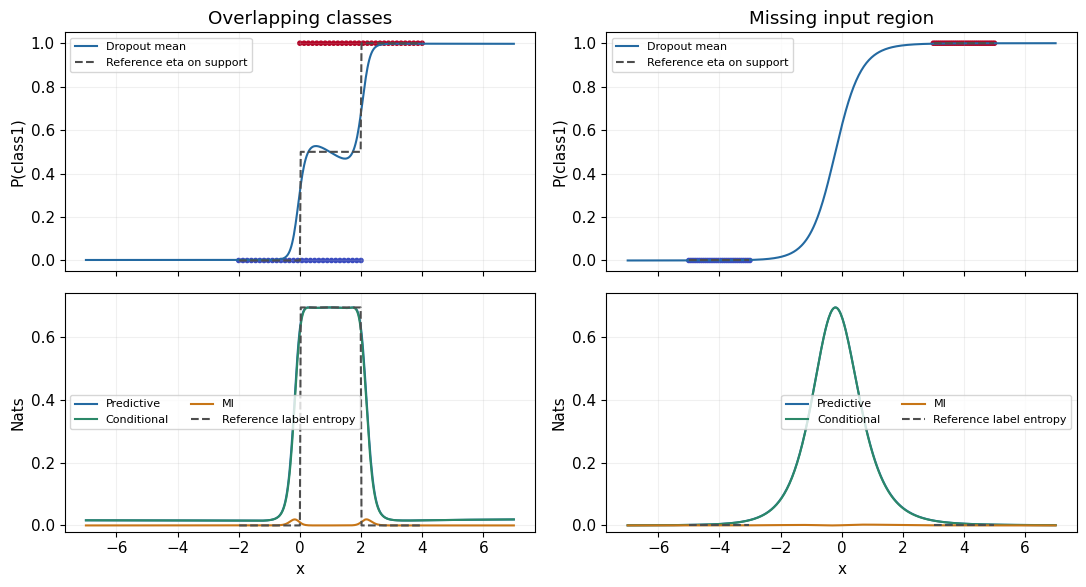

In [24]:
def reference_eta(grid, end_points):
    density = torch.zeros(len(grid), 2, dtype=grid.dtype)
    for label, ranges in end_points.items():
        for left, right in ranges:
            density[:, label] += ((grid[:, 0] > left) & (grid[:, 0] < right)).to(
                grid.dtype
            ) / (right - left)
    support = density.sum(-1) > 0
    eta = torch.full((len(grid),), float("nan"), dtype=grid.dtype)
    eta[support] = density[support, 1] / density[support].sum(-1)
    return eta, support


if RUN_APPENDICES and ready(1, 2):
    scenarios = [
        ("Overlapping classes", {0: [[-2, 2]], 1: [[0, 4]]}),
        ("Missing input region", {0: [[-5, -3]], 1: [[3, 5]]}),
    ]
    fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
    grid = torch.linspace(-7, 7, 501)[:, None]
    for column, (name, end_points) in enumerate(scenarios):
        x, y = interval_data(end_points)
        model, _ = fit_toy(x, y, seed=50 + column)
        torch.manual_seed(60 + column)
        terms = uncertainty_terms(mc_probabilities(model, grid, MC_DRAWS))
        eta, support = reference_eta(grid, end_points)
        axes[0, column].plot(
            grid[:, 0], terms["mean_probability"][:, 1], color=BLUE, label="Dropout mean"
        )
        axes[0, column].plot(
            grid[:, 0], eta, color="0.3", ls="--", label="Reference eta on support"
        )
        axes[0, column].scatter(x[:, 0], y, c=y, cmap="coolwarm", s=9)
        axes[0, column].set(title=name, ylabel="P(class1)", ylim=(-0.05, 1.05))
        for key, label, color in [
            ("predictive_entropy", "Predictive", BLUE),
            ("expected_entropy", "Conditional", GREEN),
            ("mutual_information", "MI", ORANGE),
        ]:
            axes[1, column].plot(grid[:, 0], terms[key], label=label, color=color)
        safe_eta = eta[support]
        true_entropy = -(
            torch.special.xlogy(safe_eta, safe_eta)
            + torch.special.xlogy(1 - safe_eta, 1 - safe_eta)
        )
        truth = torch.full_like(eta, float("nan"))
        truth[support] = true_entropy
        axes[1, column].plot(
            grid[:, 0], truth, color="0.3", ls="--", label="Reference label entropy"
        )
        axes[1, column].set(xlabel="x", ylabel="Nats", ylim=(-0.02, 0.74))
        axes[0, column].legend(fontsize=8)
        axes[1, column].legend(fontsize=8, ncol=2)
    plt.tight_layout()
    show_figure(fig, "geometry_scenarios")


## Appendix B. Monte Carlo budget and batch redundancy

For a fixed fitted model and input, the probability mean has an iid MC SE
$s_p/\sqrt T$. Entropy and MI are nonlinear plug-in estimates and need not
obey an identical finite-sample SE formula. A single draw always gives zero
estimated disagreement. Increasing $T$ can stabilize acquisition rankings,
but cannot fix an inadequate approximate posterior.

The repeated experiment below changes only the dropout draws and their count.
It does not refit the model or collect labels. Its reference is a long MC
estimate under this model, not an exact Bayesian posterior quantity.


In [25]:
if RUN_APPENDICES and ready(1, 2):
    points = torch.tensor([[-4.0], [-1.0], [1.7], [6.0]])
    torch.manual_seed(70)
    long_draws = mc_probabilities(toy_model, points, 5000)
    reference = uncertainty_terms(long_draws)["mutual_information"]
    rows = []
    for count in [1, 5, 20, 100, 500]:
        estimates = []
        for repeat in range(30):
            torch.manual_seed(7100 + 100 * count + repeat)
            draws = mc_probabilities(toy_model, points, count)
            estimate = categorical_entropy(draws.mean(0)) - categorical_entropy(draws).mean(0)
            estimates.append(estimate)
        estimates = torch.stack(estimates)
        rows.append(
            [
                count,
                estimates[:, 1].mean().item(),
                estimates[:, 1].std().item(),
                reference[1].item(),
            ]
        )
    table(
        [
            "MC draws",
            "Mean MI estimate at x=-1",
            "SD across MC repetitions",
            "5000-draw reference",
        ],
        rows,
    )


| MC draws | Mean MI estimate at x=-1 | SD across MC repetitions | 5000-draw reference |
| --- | --- | --- | --- |
| 1 | 0 | 0 | 0.079189 |
| 5 | 0.07639 | 0.078927 | 0.079189 |
| 20 | 0.074162 | 0.035377 | 0.079189 |
| 100 | 0.079812 | 0.014086 | 0.079189 |
| 500 | 0.07689 | 0.0062935 | 0.079189 |

For a batch $B$, joint information involves the joint predictive distribution
of all its labels. Two almost identical inputs can each have a large individual
BALD score while providing overlapping information. Our top-$k$ task uses
pointwise scores; it is not BatchBALD [4]. A diversity heuristic can reduce
neighbour redundancy but is not automatically a joint-information estimator.

Uncertainty is also not a universal out-of-distribution detector. A network
can extrapolate confidently, and a wrong approximation can make all its
stochastic predictions agree. Reliability must be evaluated against a stated
task, reference distribution, and scoring rule. Neither a compelling plot
nor high test accuracy alone establishes calibrated probabilities.


## References and attribution

[1] Yarin Gal and Zoubin Ghahramani.
[Dropout as a Bayesian Approximation: Representing Model Uncertainty in Deep Learning](https://proceedings.mlr.press/v48/gal16.html).
ICML, 2016.

[2] Neil Houlsby, Ferenc Huszár, Zoubin Ghahramani, and Máté Lengyel.
[Bayesian Active Learning for Classification and Preference Learning](https://arxiv.org/abs/1112.5745).
2011.

[3] Yarin Gal, Riashat Islam, and Zoubin Ghahramani.
[Deep Bayesian Active Learning with Image Data](https://proceedings.mlr.press/v70/gal17a.html).
ICML, 2017.

[4] Andreas Kirsch, Joost van Amersfoort, and Yarin Gal.
[BatchBALD: Efficient and Diverse Batch Acquisition for Deep Bayesian Active Learning](https://proceedings.neurips.cc/paper/2019/hash/95323660ed2124450caaac2c46b5ed90-Abstract.html).
NeurIPS, 2019.

The original interval dictionary, observation grid, sigmoid architecture,
dropout placement, and training schedule are adapted from the first example
in `spring_2025/seminar_ue_en.ipynb`. The supplied
`Sk_BML_BNN_ActiveLearning_Intro_201125 (2).ipynb`, credited there to Ivan
Nazarov, motivates the MNIST active-learning comparison. The new notes add
aligned exercises and solutions, coherent toy function draws, stable entropy,
explicit information access, paired repeats, and independent evaluation.
Both source notebooks are retained as supplied.
